# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [3]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque
import os
from scipy.io import loadmat
import time
from scipy.interpolate import griddata
from scipy.interpolate import RegularGridInterpolator
import numpy as np
import matplotlib.pyplot as plt




In [4]:
# Parameters
tau = 0.02
discount = 0.95
w1, w2, w3, w4 = 1.5, 0.5, 0.8,0.3
alpha = 0.1
beta = 2.0
state_dim = 6
num_agents = 4
buffer_size = 100000
batch_size = 64
max_episodes = 2000
max_steps = 500
constV =3 # constant speed
wind_scale_fac = 10
Dim = 1550
LowDim = 50
# known target positions
Tpos = np.array([[1430, 1200], [1000, 800], [500, 400], [200, 1500]])


# =====================================================================
# 1) Global switches ---------------------------------------------------
# =====================================================================
USE_DISCRETE_SPEEDS   = False   # 3‑level thrust ‑ keeps discrete action space
USE_CONTINUOUS_THRUST = True  # 2‑D thrust head    (set True → overrides above)

assert not (USE_DISCRETE_SPEEDS and USE_CONTINUOUS_THRUST), "Pick one mode!"

In [5]:
# =====================================================================
# 2) Action‑space definition ------------------------------------------
# =====================================================================
num_headings = 17
if USE_DISCRETE_SPEEDS:
    speeds = [0.0, 1.0, 3.0]              # hover / cruise / dash
    action_dim = num_headings * len(speeds)  # 27
else:
    # Continuous thrust: actor predicts Δvx, Δvy (normalised)
    thrust_max = 7                # m/s equivalent thrust capability
    action_dim = 2                         # Δvx, Δvy

state_dim  = 6                             # pos_x, pos_y, v_x, v_y, w_x, w_y
num_agents = 4
print(action_dim)

2


In [6]:
# ============================================================================================
# Load the wind data
# ============================================================================================
# the present path
mainfolder = os.getcwd()
# Load wind data from .mat files
def plot_vel_vector(directory=mainfolder+'/OneDrive_1_8-7-2024', frame_range=(7, 7)):
    if not os.path.exists(directory):
        print(f"Directory {directory} not found, using synthetic wind data.")
        x = np.linspace(0, 1600, 20)
        y = np.linspace(0, 1600, 20)
        px, py = np.meshgrid(x, y)
        pvx = np.sin(px / 1600 * 2 * np.pi) * 2
        pvy = np.cos(py / 1600 * 2 * np.pi) * 2
        return px.flatten(), py.flatten(), pvx.flatten(), pvy.flatten()

    px, py, pvx, pvy = [], [], [], []
    for frame in range(frame_range[0], frame_range[1] + 1):
        # Add zero-padding to frame number (e.g., 006.mat)
        mat_file = os.path.join(directory, f"{frame:05d}.mat")
        if not os.path.exists(mat_file):
            print(f"Warning: {mat_file} not found, skipping.")
            continue
        try:
            data = loadmat(mat_file)
            p = data['p']  # Shape: (2, N)
            px.append(p[0, :])
            py.append(p[1, :])
            pvx.append(data['pvx'].flatten())
            pvy.append(data['pvy'].flatten())
        except Exception as e:
            print(f"Error reading {mat_file}: {e}")
            continue
    if not px:  # If no files were loaded
        raise FileNotFoundError("No valid .mat files found in directory.")
    px = np.concatenate(px)
    py = np.concatenate(py)
    pvx = np.concatenate(pvx)
    pvy = np.concatenate(pvy)
    return px, py, pvx, pvy

[px, py, pvx, pvy] = plot_vel_vector()
print(f"px shape: {px.shape}, py shape: {py.shape}, pvx shape: {pvx.shape}, pvy shape: {pvy.shape}")

# construct a grid for the wind data scattered in 2D space
# Create a new grid to interpolate onto
grid_x, grid_y = np.mgrid[0:1600:16, 0:1600:16]  # 100x100 grid
# Interpolate the velocity components onto the new grid
grid_vx = griddata((px,py), pvx, (grid_x, grid_y), method='linear')
grid_vy = griddata((px,py), pvy, (grid_x, grid_y), method='linear')
# Replace NaN values with 0 (correct syntax)
grid_vx = np.nan_to_num(grid_vx, nan=0.0)  # Fills NaNs with 0
grid_vy = np.nan_to_num(grid_vy, nan=0.0)
interp_fvx = RegularGridInterpolator((grid_x[:,0], grid_y[0,:]), grid_vx, method='linear') # interpolator for vx
interp_fvy = RegularGridInterpolator((grid_x[:,0], grid_y[0,:]), grid_vy, method='linear')

px shape: (9878,), py shape: (9878,), pvx shape: (9878,), pvy shape: (9878,)


In [7]:
#============================================================================================
#==================================Neural Networks===========================================
#============================================================================================

# Actor Network
# map an agent's state (6D: position, velocity, wind velocity) to an action probabilities (9D)
# Input: state_dim = 6
# Output: action_dim = 27
class ActorDiscrete(nn.Module):
    """Maps 6‑D state → 27 logits (3 speeds × 9 headings)."""
    def __init__(self,state_dim,action_dim):
        super(ActorDiscrete,self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128), nn.ReLU(),
            nn.Linear(128, 128),       nn.ReLU(),
            nn.Linear(128, action_dim),
            nn.Softmax(dim=-1)
        )
    def forward(self, x):
        return self.net(x)

class ActorContinuous(nn.Module):
    """Maps 6‑D state → Δvx, Δvy in [‑1,1]; scale later to thrust_max."""
    def __init__(self,state_dim,action_dim):
        super(ActorContinuous,self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128), nn.ReLU(),
            nn.Linear(128, 128),       nn.ReLU(),
            nn.Linear(128, action_dim),
            nn.Tanh()                 # outputs in (‑1,1)
        )
    def forward(self, x):
        return self.net(x)

# Pick actor class -----------------------------------------------------
Actor = ActorContinuous if USE_CONTINUOUS_THRUST else ActorDiscrete

# Critic Network
# map a global state (24D: 6D for each of the 4 agents) and action (36D: 9D for each of the 4 agents) to a Q-value
# Estimates the Q-value for a given global state and action, guiding actor optimization.
# Input: state_dim * num_agents + action_dim * num_agents = 6 * 4 + 9 * 4 = 60
# Output: 1D Q-value
class Critic(nn.Module):
    def __init__(self, state_dim, action_dim, num_agents):
        super(Critic, self).__init__()
        total_state_dim = state_dim * num_agents
        total_action_dim = action_dim * num_agents
        self.net = nn.Sequential(
            nn.Linear(total_state_dim + total_action_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 1)
        )

    def forward(self, state, action):
        x = torch.cat([state, action], dim=-1)
        return self.net(x)


In [8]:
#============================================================================================
#==================================Action Execution==========================================
#============================================================================================

#comments: is it better to encourage agents to maintain a higher speed?
def act(action, time, int_vx, int_vy, wind_v, pos_x, pos_y, px, py, pvx, pvy):
    # mass = 1
    if USE_CONTINUOUS_THRUST:
        return act_continuous(action, wind_v, pos_x, pos_y)
    else:
        return act_discrete(action, int_vx, int_vy, wind_v, pos_x, pos_y,time)

    # =====================================================================
# 5) act() helpers -----------------------------------------------------
# =====================================================================

def act_discrete(action_idx, prev_int_vx, prev_int_vy, wind_v, pos_x, pos_y,time):
    """Decode discrete action → engine‑frame velocity, new position."""
    _heading_ranges = {
    0: (0, 22),       1: (23, 45),     2: (46, 68),     3: (69, 91),
    4: (92, 114),     5: (115, 137),   6: (138, 160),   7: (161, 183),
    8: (184, 206),    9: (207, 229),   10: (230, 252),  11: (253, 275),
    12: (276, 298),   13: (299, 321),  14: (322, 344),  15: (345, 359),
    16: (None, None)  # maintain heading
}



    speed_idx   = action_idx // num_headings
    heading_idx = action_idx %  num_headings
    constV      = speeds[speed_idx]

    if heading_idx == 16:  # maintain previous direction (hover if V=0)
        if constV == 0:
            int_vx, int_vy = 0.0, 0.0
            angle_deg = 0.0
        else:
            angle_deg = np.degrees(np.arctan2(prev_int_vy, prev_int_vx))
            int_vx = constV * np.cos(np.radians(angle_deg))
            int_vy = constV * np.sin(np.radians(angle_deg))
    else:
        a_low, a_hi = _heading_ranges[heading_idx]
        angle_deg   = np.random.randint(a_low, a_hi)
        int_vx      = constV * np.cos(np.radians(angle_deg))
        int_vy      = constV * np.sin(np.radians(angle_deg))

    # ground velocity = engine + wind
    vx, vy = int_vx + wind_v[0], int_vy + wind_v[1]
    new_x, new_y = pos_x + (vx*time), pos_y + (vy*time)
    new_x = np.clip(new_x, LowDim, Dim)
    new_y = np.clip(new_y, LowDim, Dim)





    # Interpolate wind velocity
    wvx = interp_fvx([new_x,new_y]).item() * wind_scale_fac
    wvy = interp_fvy([new_x,new_y]).item() * wind_scale_fac
    w_dir = np.degrees(np.arctan2(wvy, wvx))
    return new_x, new_y, vx, vy, w_dir,action, angle_deg, wvx, wvy

def act_continuous(action, wind_v, pos_x, pos_y):
    """Continuous thrust: delta_v already scaled to ±thrust_max."""
    delta_v = action * thrust_max  # important
    int_vx, int_vy = delta_v
    vx = int_vx + wind_v[0]
    vy = int_vy + wind_v[1]
    new_x = pos_x + vx
    new_y = pos_y + vy

    new_x = np.clip(new_x, LowDim, Dim)
    new_y = np.clip(new_y, LowDim, Dim)

    wvx = interp_fvx([new_x, new_y]).item() * wind_scale_fac
    wvy = interp_fvy([new_x, new_y]).item() * wind_scale_fac
    w_dir = np.degrees(np.arctan2(wvy, wvx))

    return new_x, new_y, vx, vy, w_dir, int_vx, int_vy, wvx, wvy





In [9]:


def compute_r_coverage_from_entropy(visit_grid):
    flat = visit_grid.flatten()
    probs = flat / (np.sum(flat) + 1e-8)  # normalize
    entropy = -np.sum(probs * np.log(probs + 1e-8))
    max_entropy = np.log(flat.shape[0])
    return entropy / (max_entropy + 1e-8)  # normalize to [0,1]


In [10]:
def update_visit_grid(agent_positions, visit_grid, cell_size=32):
    for pos in agent_positions:
        i = int(pos[0] // cell_size)
        j = int(pos[1] // cell_size)
        if 0 <= i < visit_grid.shape[0] and 0 <= j < visit_grid.shape[1]:
            visit_grid[i, j] += 1


In [12]:
def compute_turning_penalty_individual(prev_vels, new_vels, turn_history,
                                       angle_threshold=np.pi/6, count_step=30, speed_weight=True):
    penalties = []
    num_agents = len(prev_vels)
    for j in range(num_agents):
        pv = prev_vels[j]
        nv = new_vels[j]

        # compute raw turn angle
        if np.linalg.norm(pv) > 1e-6 and np.linalg.norm(nv) > 1e-6:
            cos_angle = np.dot(pv, nv) / (np.linalg.norm(pv) * np.linalg.norm(nv))
            cos_angle = np.clip(cos_angle, -1.0, 1.0)
            angle = np.arccos(cos_angle)
        else:
            angle = 0.0

        # threshold small angles
        angle = max(0.0, angle - angle_threshold)

        # --- store in history ---
        turn_history[j].append(angle)
        if len(turn_history[j]) > count_step:
            turn_history[j] = turn_history[j][-count_step:]  # keep last `count_step` angles

        # only compute penalty if enough history
        if len(turn_history[j]) >= count_step:
            smoothed_angle = np.mean(turn_history[j])
            if speed_weight:
                smoothed_angle *= np.linalg.norm(nv)
        else:
            smoothed_angle = 0.0  # no penalty yet

        penalties.append(smoothed_angle)

    return penalties



In [30]:
from collections import deque
import numpy as np

class LoopDetector:
    def __init__(self, vortex_penalty=5.0, decay=0.95, window_size=50):
        self.prev_angle = None
        self.dtheta_window = deque(maxlen=window_size)
        self.total_loops = 0
        self.cumulative_penalty = 0.0  # accumulated penalty
        self.vortex_penalty = vortex_penalty
        self.decay = decay
        self.penalty_scale = 5
        self.window_size = window_size

    def update(self, vx, vy):
        """
        vx, vy: current agent velocity components
        Returns the cumulative penalty for this agent.
        """
        angle = np.arctan2(vy, vx)
        new_loops = 0

        if self.prev_angle is not None:
            # compute delta angle, unwrapped
            dtheta = np.unwrap([self.prev_angle, angle])[1] - self.prev_angle
            self.dtheta_window.append(dtheta)

            # check if recent turning adds up to a full loop
            if abs(sum(self.dtheta_window)) >= 2*np.pi:
                new_loops += 1
                self.total_loops += 1
                self.dtheta_window.clear()  # reset after detecting loop

        self.prev_angle = angle

        # Update cumulative penalty with decay
        self.cumulative_penalty = self.cumulative_penalty * self.decay + new_loops * self.vortex_penalty
        # inside LoopDetector.update
        turn_load = sum(abs(x) for x in self.dtheta_window)
        frac = min(turn_load / (2*np.pi), 1.0)   # how much of a circle in the window
        step_penalty = self.penalty_scale * frac # penalty for this step only

        return step_penalty

        #return self.cumulative_penalty


In [14]:
def compute_curvature(prev_vel, curr_vel, motion_scale=1e-6):
    """
    prev_vel, curr_vel: np.array shape (n, 2)
    motion_scale: avoids division by zero
    Returns curvature per agent
    """
    n = prev_vel.shape[0]
    unit_prev = prev_vel / (np.linalg.norm(prev_vel, axis=1, keepdims=True) + motion_scale)
    unit_curr = curr_vel / (np.linalg.norm(curr_vel, axis=1, keepdims=True) + motion_scale)
    diff = unit_curr - unit_prev
    curvature = np.linalg.norm(diff, axis=1)
    return curvature


In [31]:
#============================================================================================
#==================================Reward Functions==========================================
#============================================================================================

# compute the total reward for each agent, combining individual and centralized rewards
# The individual reward is based on the distance to the nearest target, while the centralized reward considers coverage, efficiency, and separation.
# w1, w2, w3, alpha: reward weights and scaling factor
# ---------------------------------------------------------------------------
# NEW ‑‑ full replacement
# ---------------------------------------------------------------------------

def compute_total_reward(agent_positions,
                         prev_agent_positions,         # NEW ← pass last‑step positions
                         target_positions,
                         visited_targets,
                         dvel, w_x_y,
                         visit_grid,recent_visit_grid,prev_vels,new_vels,w1, w2, w3,w4,
                         alpha, beta, count_step=1):
    """
    Returns:
        total_reward_per_agent (np.array shape (n,))
        visited_targets       (updated list of bool)
    """
    n = agent_positions.shape[0]
    r_i = np.zeros(n)

    # --- parameters you may tune ---
    proximity_threshold = 100.0
    hit_reward          = 450.0
    STRAIGHT_LINE_PENALTY = 0.05  # NEW: penalty for low velocity change
    safe_distance       = 20.0
    # --------------------------------

    # ---------- 1)  INDIVIDUAL PART ----------
    for i in range(n):
        # distance to *nearest* target
        #distances = np.linalg.norm(target_positions - agent_positions[i], axis=1)
        #min_idx   = np.argmin(distances)
        #d_now     = distances[min_idx]
        # ----- Only consider *unvisited* targets -----
        unvisited = [j for j, v in enumerate(visited_targets) if not v]
        if unvisited:
            distances = np.linalg.norm(target_positions[unvisited] - agent_positions[i], axis=1)
            min_idx_local = np.argmin(distances)
            min_idx = unvisited[min_idx_local]
            d_now = distances[min_idx_local]

            # (A) Hit a new target
            if d_now < proximity_threshold:
                r_i[i] = hit_reward
                visited_targets[min_idx] = True
            else:
                # (B) Optional shaping reward (can uncomment later)
                # d_prev = np.linalg.norm(target_positions[min_idx] - prev_agent_positions[i])
                # r_i[i] = (d_prev - d_now) / 1600.0
                r_i[i] += 0  # No shaping for now
        else:
            # No more targets to go after → you may penalize idle behavior
            r_i[i] += 400  # Optional terminal penalty



        # (A) hit a *new* target
        #if d_now < proximity_threshold and not visited_targets[min_idx]:
            #r_i[i] = hit_reward
            #visited_targets[min_idx] = True

        # (B) shaping: distance improvement since last step
        #else:
            #r_i[i] = 0
            #d_prev = np.linalg.norm(target_positions[min_idx] - prev_agent_positions[i])
            #r_i[i] = (d_prev - d_now) / Dim      # +ve if closer


        # (C) optional wind‑alignment bonus (unchanged from code)
        #if np.linalg.norm(dvel[i]) > 0 and np.linalg.norm(w_x_y[i]) > 0:
            cos_theta = np.dot(dvel[i], w_x_y[i])
        MAX_PENALTY = 0.1  # You can tune this
        step_penalty = (count_step / max_steps) * MAX_PENALTY
        r_i[i] -= step_penalty
        v_i = new_vels[i]

        loop_penalty = loop_detectors[i].update(v_i[0], v_i[1])

        r_i[i] -= loop_penalty




             # Compute individual penalties
        #r_turn = compute_turning_penalty_individual(prev_vels, new_vels, turn_history)
        # Example: coverage reward already computed per agent
        # r_cov = [coverage_reward(agent_i) for agent_i in range(num_agents)]

        # Combine into individual reward per agent
        #r_i[i] -= w3*r_turn[i]
        # (C) Wind Alignment Bonus
        #wind_norm = np.linalg.norm(w_x_y[i])
        #agent_vel_norm = np.linalg.norm(dvel[i])
        #if wind_norm > 0 and agent_vel_norm > 0:
            #cos_theta = np.dot(dvel[i], w_x_y[i]) / (agent_vel_norm * wind_norm)
            #r_i[i] += beta * cos_theta  # encourage alignment

        # (D) Straight-line movement penalty
        #if count_step > 1 and agent_vel_norm > 0:
            #accel_mag = np.linalg.norm(dvel[i])  # velocity change since last step
            #if accel_mag < 1e-2:  # almost no acceleration = straight line
                #r_i[i] -= STRAIGHT_LINE_PENALTY

                # (D) Straight-line movement penalty based on heading similarity
        #prev_v = prev_agent_positions[i] - agent_positions[i]  # Estimate last velocity
        #norm_prev_v = np.linalg.norm(prev_v)
        ###heading_cos = np.dot(prev_v, dvel[i]) / (norm_prev_v * norm_curr_v)
            #if heading_cos > 0.98:  # Nearly same direction = straight line
                #r_i[i] -= STRAIGHT_LINE_PENALTY  # Strong penalty (e.g. 10, 20, or 50)


        # In reward function:
        #boundary_penalty = -50.0
        #for i in range(n):
            #x, y = agent_positions[i]
            #if x < LowDim + 50 or x > Dim - 50 or y < LowDim + 50 or y > Dim - 50:
                #boundary_penalty -= 0.1  # or scale with distance
       # r_i[i] += boundary_penalty



        #else:
            #cos_theta = 0.0
        #r_i[i] += beta * cos_theta



    # ---------- 2)  TEAM PART ----------
    r_central,r_coverage,r_separation = compute_centralized_reward(agent_positions,
                                           target_positions,
                                           visit_grid,recent_visit_grid,prev_vels,new_vels,w1, w2, w3,
                                           w4,safe_distance)     # safe_distance passed in

    team_bonus =  r_central          # <‑‑ *no* division by num_agents
    THRUST_COST_COEF = 0.005  # reward -= c * |engine_vel|²  (tune 1e‑3…1e‑2)
    #r_i = beta * r_i



    return r_i + team_bonus, visited_targets, r_i, r_central, r_coverage, r_separation,loop_penalty


# Compute a shared reward for all agents, considering coverage, efficiency, and separation
# Coverage (r_coverage): Sums the minimum distance from each agent to any other agent (excluding self), encouraging agents to spread out.
# Efficiency (r_efficiency): Sums the negative minimum distance from each agent to the target positions, promoting proximity to targets.
# Separation (r_separation): Penalizes agents that are too close to each other, promoting separation.


def compute_centralized_reward(agent_positions, target_positions, visit_grid,recent_visit_grid,prev_vels,new_vels,w1, w2, w3,w4,safe_distance=40):
    n = agent_positions.shape[0]

    # Encourage spreading out
    #min_distances = np.full(n, np.inf)
    #for i in range(n):
        #distances = np.linalg.norm(agent_positions - agent_positions[i], axis=1)
        #distances[i] = np.inf
        #min_distances[i] = np.min(distances)
    #r_coverage = np.mean(min_distances) / Dim
    # ---------- 1) Coverage via entropy ----------
    r_coverage = compute_r_coverage_from_entropy(visit_grid)  # NEW

    # Encourage proximity to targets
    #r_efficiency = 0
    #for i in range(n):
        #distances = np.linalg.norm(target_positions - agent_positions[i], axis=1)
        #r_efficiency += (Dim - np.min(distances)) / Dim  # normalized proximity
    #r_efficiency /= n

    # Encourage agents to cover space evenly — using entropy over a 2D grid

    min_safe_distance = 50.0  # You can tune this
    cluster_penalty = 0.0

    for i in range(n):
        for j in range(i + 1, n):
            dist = np.linalg.norm(agent_positions[i] - agent_positions[j])
            if dist < min_safe_distance:
                cluster_penalty += (min_safe_distance - dist) / min_safe_distance

     # penalties
    #r_rev = compute_revisit_penalty(agent_positions, recent_visit_grid)
    #r_turn = compute_turning_penalty(prev_vels, new_vels)

    # Normalize over all pairs
    r_separation = cluster_penalty / (n * (n - 1) / 2)















    # Encourage agents to be safely separated (e.g. more than 80 units apart)
    #agent_distances = np.linalg.norm(agent_positions[:, np.newaxis] - agent_positions, axis=2)
    #agent_distances[agent_distances == 0] = np.inf
    #min_agent_distances = np.min(agent_distances, axis=1)
    #safe_distance = 20.0
    #r_separation = np.mean(np.clip(min_agent_distances - safe_distance, 0, Dim)) / Dim

    # Return full breakdown
    return (
        w1 * r_coverage - w4 * r_separation,
        r_coverage,
        r_separation
    )


In [32]:
#============================================================================================
#====================================Initialization==========================================
#============================================================================================

# Selects GPU (cuda) if available, else CPU, for network computations.
# Creates four actor networks and four target actor networks (one per agent).
# Creates a critic network and a target critic network for centralized training.
# Moves all networks to the selected device.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
actor_networks = [Actor(state_dim, action_dim).to(device) for _ in range(num_agents)]
target_actors = [Actor(state_dim, action_dim).to(device) for _ in range(num_agents)]
critic_network = Critic(state_dim, action_dim, num_agents).to(device)
target_critic = Critic(state_dim, action_dim, num_agents).to(device)

# Copy initial weights from main networks to target networks using load_state_dict
for a, ta in zip(actor_networks, target_actors):
    ta.load_state_dict(a.state_dict())
target_critic.load_state_dict(critic_network.state_dict())

# Optimizers
# Uses Adam optimizers with learning rates (0.004 for actors, 0.005 for critic).
actor_optimizers = [optim.Adam(a.parameters(), lr=0.0001) for a in actor_networks]
critic_optimizer = optim.Adam(critic_network.parameters(), lr=0.0002)

# Replay Buffer
# Initializes a deque with maxlen = 100000 to store experiences (global states, actions, rewards, next states).
replay_buffer = deque(maxlen=50000)


# Initialize Agents
# Positions (Dpos): Randomly places each agent in [20, 1500] for x and y.
# Velocities (DVel): Sets initial velocity to [1, 0] for all agents.
# Wind (W_x_y): Interpolates initial wind velocities at each agent’s position

[step 001] wind  7.5 | engine 13.8 | ground 13.8 | wind>engine? False
[step 001] wind 12.5 | engine 17.7 | ground 17.7 | wind>engine? False
[step 001] wind 25.8 | engine 29.5 | ground 29.5 | wind>engine? False
[step 001] wind 29.4 | engine 27.3 | ground 27.3 | wind>engine? True
[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 0] r_central: -0.000 | coverage: -0.000, separation: 0.000
[step 002] wind  4.7 | engine 10.6 | ground 10.6 | wind>engine? False
[step 002] wind  9.7 | engine 16.1 | ground 16.1 | wind>engine? False
[step 002] wind 23.9 | engine 35.7 | ground 35.7 | wind>engine? False
[step 002] wind 28.0 | engine 38.0 | ground 38.0 | wind>engine? False
[dbg] r_i: [-0.477 -0.101 -0.314 -0.266]  loop_penalty: 0.266
[ep 0] r_central: 0.269 | coverage: 0.179, separation: 0.000
[step 003] wind  3.8 | engine  6.1 | ground  6.1 | wind>engine? False
[step 003] wind  7.4 | engine 17.4 | ground 17.4 | wind>engine? False
[step 003] wind 20.4 | engine 31.3 | ground 31.3 | wind>engine? F

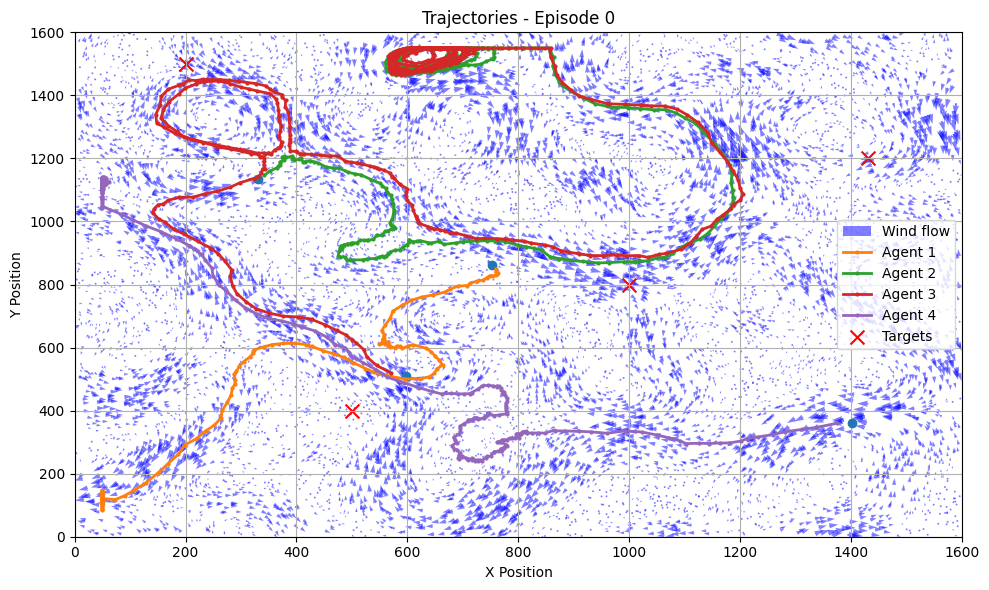

[step 001] wind 12.7 | engine  5.3 | ground  5.3 | wind>engine? True
[step 001] wind 19.5 | engine 16.4 | ground 16.4 | wind>engine? True
[step 001] wind  4.7 | engine  2.8 | ground  2.8 | wind>engine? True
[step 001] wind 12.2 | engine  2.5 | ground  2.5 | wind>engine? True
[dbg] r_i: [450.  -0.  -0.  -0.]  loop_penalty: 0.000
[ep 1] r_central: -0.000 | coverage: -0.000, separation: 0.000
[step 002] wind 13.6 | engine  5.8 | ground  5.8 | wind>engine? True
[step 002] wind 19.7 | engine  9.6 | ground  9.6 | wind>engine? True
[step 002] wind  4.9 | engine  3.2 | ground  3.2 | wind>engine? True
[step 002] wind 12.4 | engine  2.3 | ground  2.3 | wind>engine? True
[dbg] r_i: [-0.129 -0.228 -1.61  -0.038]  loop_penalty: 0.037
[ep 1] r_central: 0.269 | coverage: 0.179, separation: 0.000
[step 003] wind 14.5 | engine  6.3 | ground  6.3 | wind>engine? True
[step 003] wind 20.8 | engine 16.4 | ground 16.4 | wind>engine? True
[step 003] wind  6.2 | engine  4.6 | ground  4.6 | wind>engine? True
[

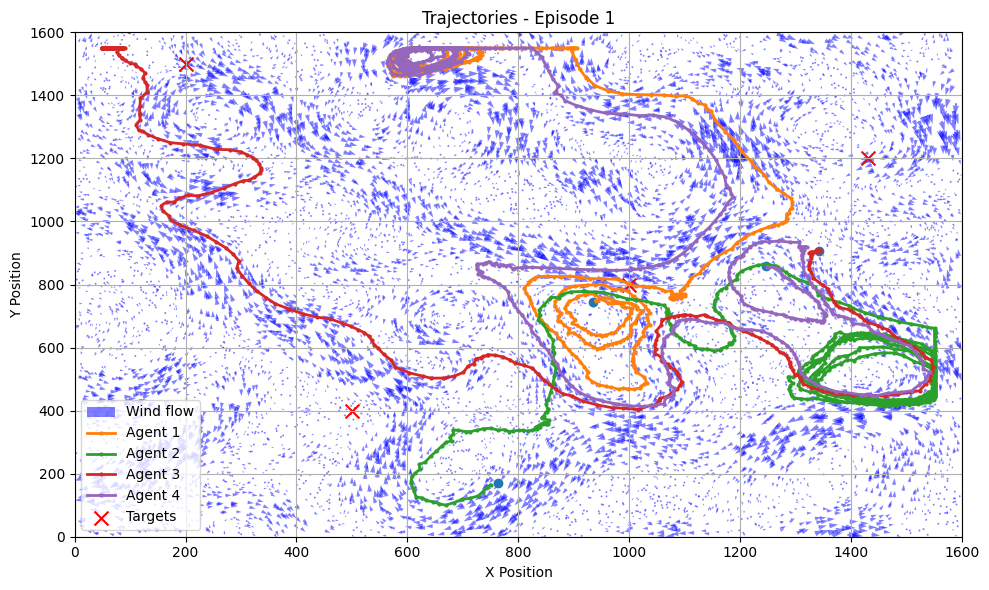

[step 001] wind 17.5 | engine 27.1 | ground 27.1 | wind>engine? False
[step 001] wind 20.6 | engine 31.0 | ground 31.0 | wind>engine? False
[step 001] wind 17.9 | engine 17.3 | ground 17.3 | wind>engine? True
[step 001] wind 16.1 | engine 12.5 | ground 12.5 | wind>engine? True
[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 2] r_central: -0.011 | coverage: -0.000, separation: 0.037
[step 002] wind 16.8 | engine 25.2 | ground 25.2 | wind>engine? False
[step 002] wind 16.3 | engine 30.3 | ground 30.3 | wind>engine? False
[step 002] wind 17.7 | engine 14.0 | ground 14.0 | wind>engine? True
[step 002] wind 16.3 | engine 11.5 | ground 11.5 | wind>engine? True
[dbg] r_i: [-0.209 -0.009 -0.241 -0.077]  loop_penalty: 0.076
[ep 2] r_central: 0.263 | coverage: 0.179, separation: 0.018
[step 003] wind 16.0 | engine 25.6 | ground 25.6 | wind>engine? False
[step 003] wind 12.1 | engine 25.9 | ground 25.9 | wind>engine? False
[step 003] wind 18.6 | engine 13.5 | ground 13.5 | wind>engine? True

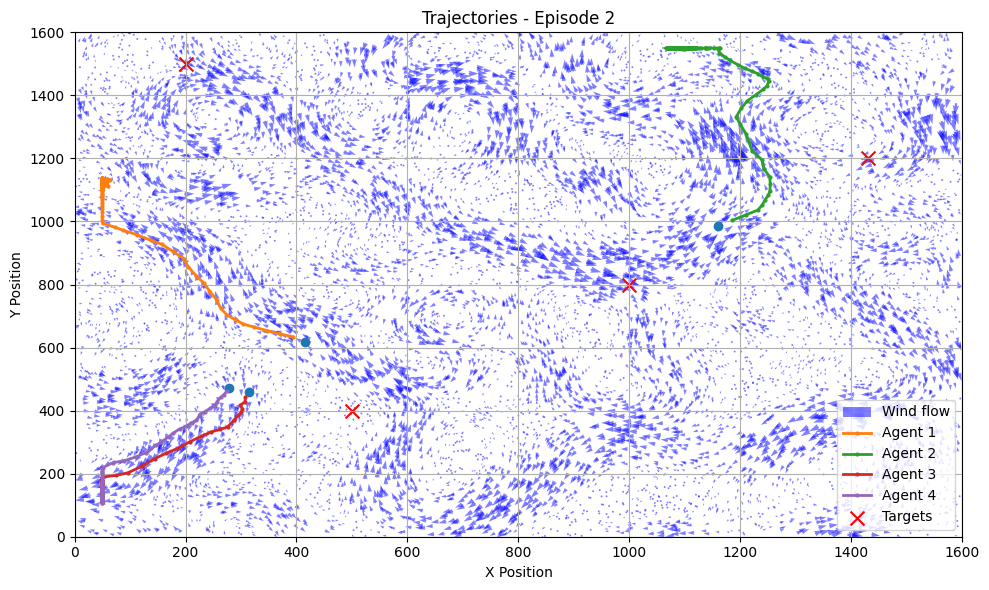

[step 001] wind 18.0 | engine 20.2 | ground 20.2 | wind>engine? False
[step 001] wind 15.6 | engine  8.2 | ground  8.2 | wind>engine? True
[step 001] wind 22.6 | engine 33.9 | ground 33.9 | wind>engine? False
[step 001] wind 22.3 | engine 14.8 | ground 14.8 | wind>engine? True
[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 3] r_central: -0.000 | coverage: -0.000, separation: 0.000
[step 002] wind 16.9 | engine 16.8 | ground 16.8 | wind>engine? True
[step 002] wind 16.2 | engine 17.9 | ground 17.9 | wind>engine? False
[step 002] wind 22.1 | engine 15.7 | ground 15.7 | wind>engine? True
[step 002] wind 23.7 | engine 28.8 | ground 28.8 | wind>engine? False
[dbg] r_i: [-0.393 -0.008 -0.051 -0.298]  loop_penalty: 0.297
[ep 3] r_central: 0.269 | coverage: 0.179, separation: 0.000
[step 003] wind 16.7 | engine 24.4 | ground 24.4 | wind>engine? False
[step 003] wind 16.1 | engine 10.1 | ground 10.1 | wind>engine? True
[step 003] wind 21.2 | engine 30.4 | ground 30.4 | wind>engine? False

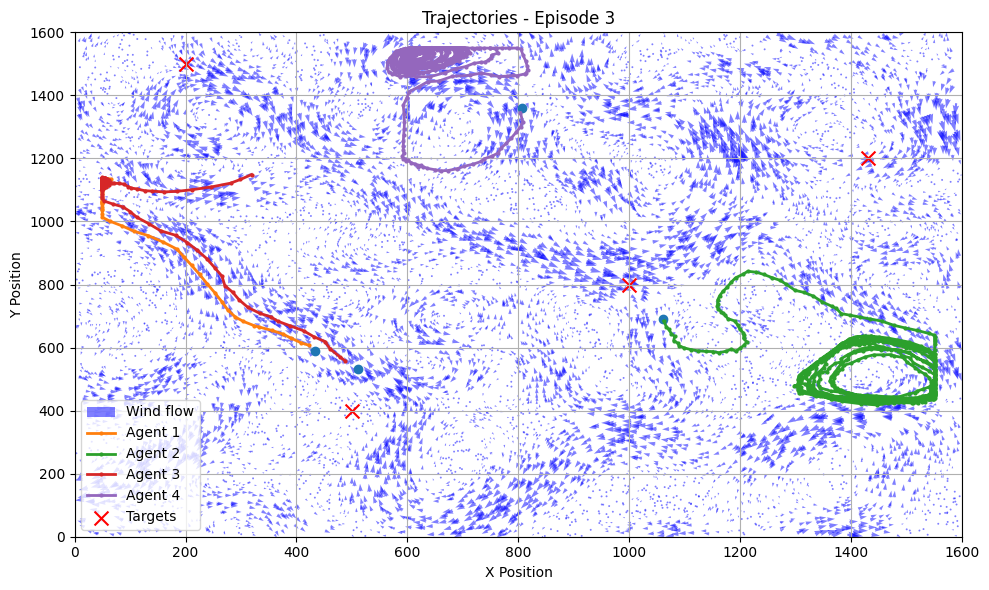

[step 001] wind 23.8 | engine 27.8 | ground 27.8 | wind>engine? False
[step 001] wind 13.3 | engine 18.1 | ground 18.1 | wind>engine? False
[step 001] wind 16.9 | engine 11.4 | ground 11.4 | wind>engine? True
[step 001] wind  9.5 | engine  1.5 | ground  1.5 | wind>engine? True
[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 4] r_central: -0.000 | coverage: -0.000, separation: 0.000
[step 002] wind 25.2 | engine 20.3 | ground 20.3 | wind>engine? True
[step 002] wind 16.1 | engine 17.4 | ground 17.4 | wind>engine? False
[step 002] wind 18.0 | engine  9.4 | ground  9.4 | wind>engine? True
[step 002] wind 10.1 | engine  5.6 | ground  5.6 | wind>engine? True
[dbg] r_i: [-0.332 -0.14  -0.099 -0.085]  loop_penalty: 0.084
[ep 4] r_central: 0.269 | coverage: 0.179, separation: 0.000
[step 003] wind 26.3 | engine 21.8 | ground 21.8 | wind>engine? True
[step 003] wind 18.3 | engine 22.0 | ground 22.0 | wind>engine? False
[step 003] wind 19.2 | engine 10.3 | ground 10.3 | wind>engine? True
[

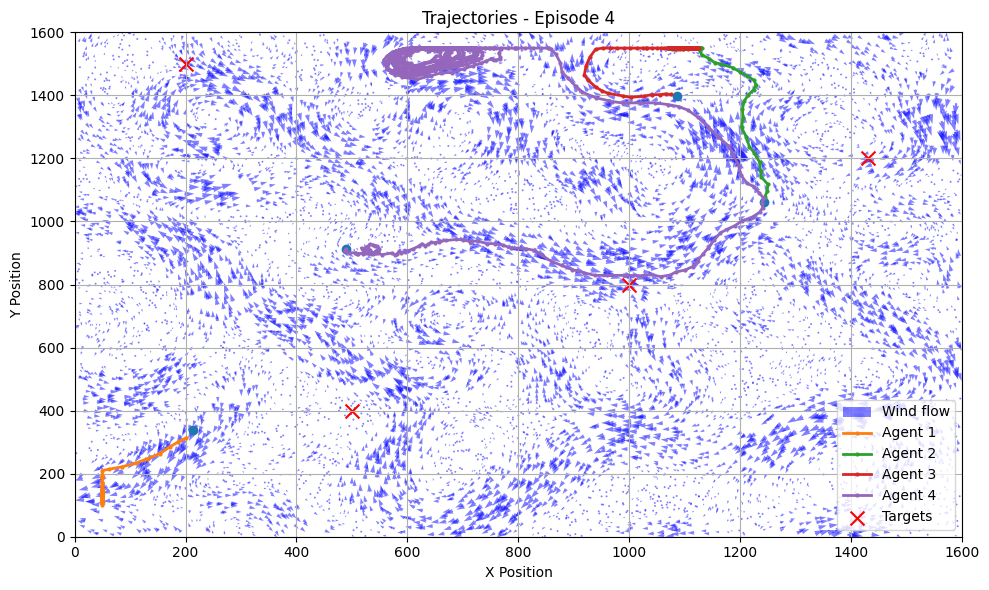

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 5] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.077 -0.313 -0.416 -0.036]  loop_penalty: 0.036
[ep 5] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.566 -0.532 -0.758 -0.074]  loop_penalty: 0.073
[ep 5] r_central: 0.336 | coverage: 0.224, separation: 0.000
[dbg] r_i: [-0.878 -0.587 -0.759 -0.723]  loop_penalty: 0.722
[ep 5] r_central: 0.414 | coverage: 0.276, separation: 0.000
[dbg] r_i: [-0.997 -0.614 -0.861 -1.19 ]  loop_penalty: 1.189
[ep 5] r_central: 0.447 | coverage: 0.298, separation: 0.000
[dbg] r_i: [-1.137 -0.623 -0.985 -1.408]  loop_penalty: 1.407
[ep 5] r_central: 0.463 | coverage: 0.309, separation: 0.000
[dbg] r_i: [-1.736 -0.67  -1.028 -1.445]  loop_penalty: 1.444
[ep 5] r_central: 0.491 | coverage: 0.327, separation: 0.000
[dbg] r_i: [-1.967 -0.679 -1.219 -1.721]  loop_penalty: 1.719
[ep 5] r_central: 0.529 | coverage: 0.353, separation: 0.000
[dbg] r_i: [-2.353 -0.905 

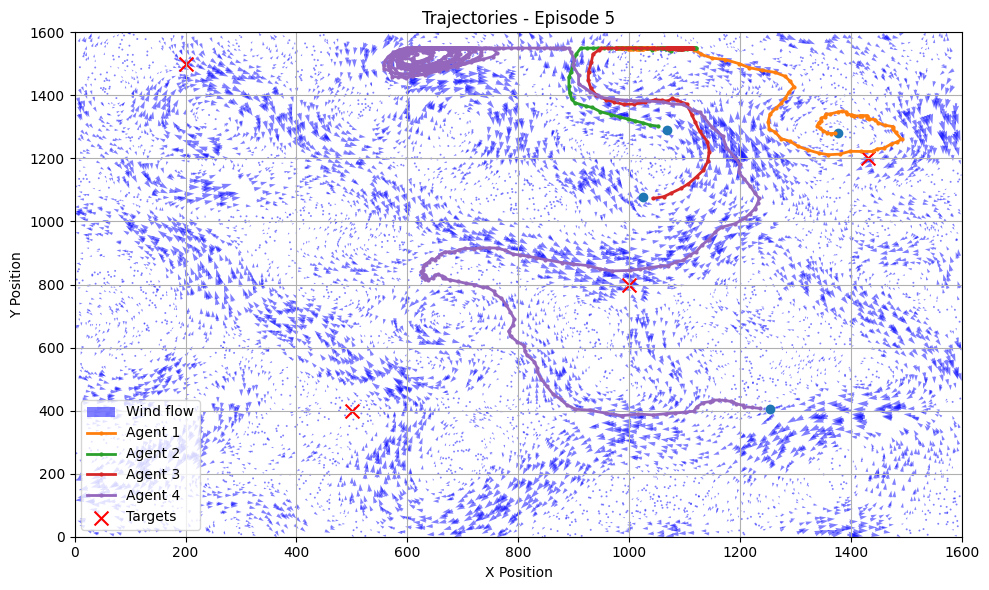

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 6] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.475 -0.271 -0.378 -0.18 ]  loop_penalty: 0.180
[ep 6] r_central: 0.264 | coverage: 0.179, separation: 0.014
[dbg] r_i: [-0.641 -0.783 -1.13  -0.437]  loop_penalty: 0.437
[ep 6] r_central: 0.330 | coverage: 0.224, separation: 0.020
[dbg] r_i: [-1.108 -0.954 -1.509 -0.584]  loop_penalty: 0.583
[ep 6] r_central: 0.382 | coverage: 0.261, separation: 0.032
[dbg] r_i: [-1.659 -1.438 -2.597 -0.609]  loop_penalty: 0.608
[ep 6] r_central: 0.412 | coverage: 0.276, separation: 0.005
[dbg] r_i: [-1.862 -1.604 -3.233 -0.629]  loop_penalty: 0.628
[ep 6] r_central: 0.428 | coverage: 0.285, separation: 0.000
[dbg] r_i: [-2.256 -1.978 -3.471 -0.87 ]  loop_penalty: 0.869
[ep 6] r_central: 0.470 | coverage: 0.313, separation: 0.000
[dbg] r_i: [-2.316 -2.033 -3.778 -1.07 ]  loop_penalty: 1.068
[ep 6] r_central: 0.511 | coverage: 0.341, separation: 0.000
[dbg] r_i: [-2.367 -2.319 

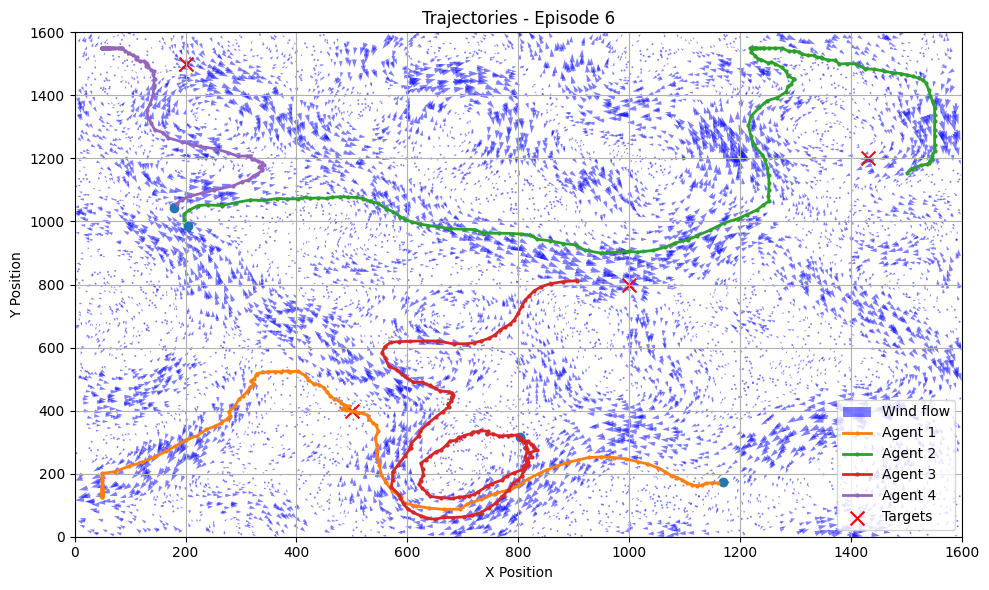

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 7] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.257 -0.366 -1.946 -0.21 ]  loop_penalty: 0.209
[ep 7] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.582 -0.43  -2.999 -0.331]  loop_penalty: 0.330
[ep 7] r_central: 0.369 | coverage: 0.246, separation: 0.000
[dbg] r_i: [-0.786 -0.715 -3.896 -0.39 ]  loop_penalty: 0.389
[ep 7] r_central: 0.392 | coverage: 0.261, separation: 0.000
[dbg] r_i: [-1.024 -1.122 -4.024 -0.45 ]  loop_penalty: 0.449
[ep 7] r_central: 0.430 | coverage: 0.287, separation: 0.000
[dbg] r_i: [-1.15  -1.679 -5.001 -0.645]  loop_penalty: 0.643
[ep 7] r_central: 0.473 | coverage: 0.315, separation: 0.000
[dbg] r_i: [-1.255 -2.328 -5.001 -0.719]  loop_penalty: 0.718
[ep 7] r_central: 0.484 | coverage: 0.322, separation: 0.000
[dbg] r_i: [-1.778 -2.36  -5.002 -0.773]  loop_penalty: 0.772
[ep 7] r_central: 0.514 | coverage: 0.342, separation: 0.000
[dbg] r_i: [-2.369 -2.404 

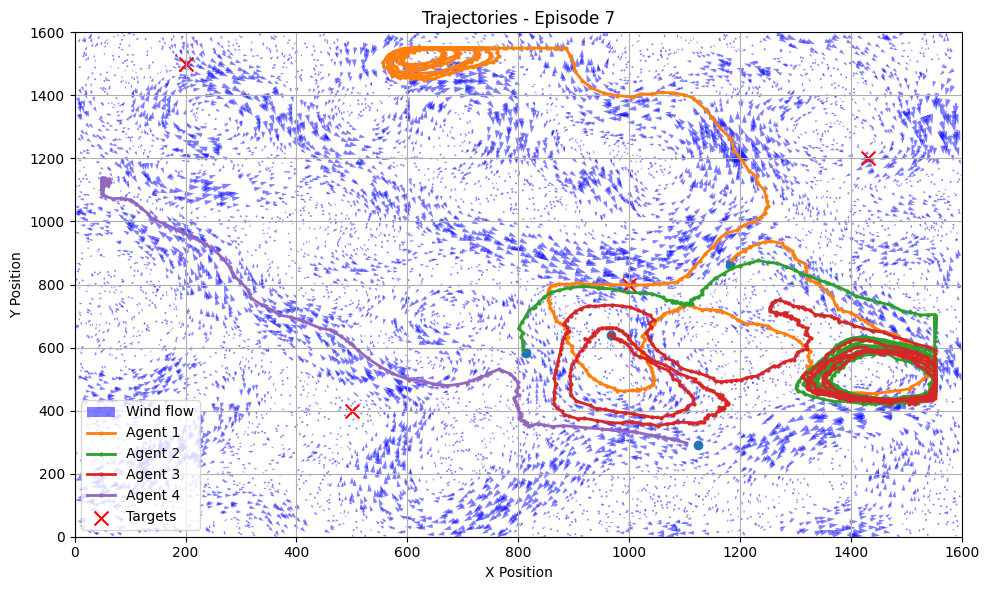

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 8] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.255 -0.137 -0.241 -0.806]  loop_penalty: 0.805
[ep 8] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.698 -0.382 -0.246 -1.158]  loop_penalty: 1.157
[ep 8] r_central: 0.369 | coverage: 0.246, separation: 0.000
[dbg] r_i: [-1.044 -0.616 -0.578 -1.291]  loop_penalty: 1.291
[ep 8] r_central: 0.392 | coverage: 0.261, separation: 0.000
[dbg] r_i: [-1.087 -0.618 -1.263 -1.502]  loop_penalty: 1.501
[ep 8] r_central: 0.430 | coverage: 0.287, separation: 0.000
[dbg] r_i: [-1.394 -0.91  -1.574 -2.53 ]  loop_penalty: 2.529
[ep 8] r_central: 0.476 | coverage: 0.317, separation: 0.000
[dbg] r_i: [-1.825 -1.84  -1.756 -2.829]  loop_penalty: 2.827
[ep 8] r_central: 0.507 | coverage: 0.338, separation: 0.000
[dbg] r_i: [-2.407 -2.037 -2.203 -3.169]  loop_penalty: 3.168
[ep 8] r_central: 0.506 | coverage: 0.338, separation: 0.000
[dbg] r_i: [-3.041 -2.087 

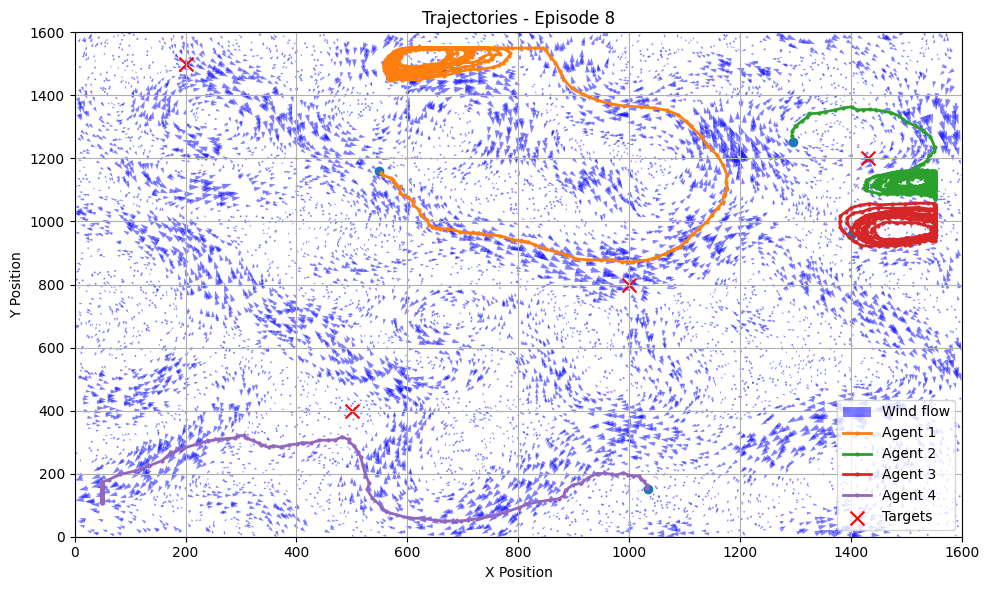

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 9] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.325 -1.775 -0.138 -0.313]  loop_penalty: 0.313
[ep 9] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.343 -2.433 -0.291 -0.737]  loop_penalty: 0.736
[ep 9] r_central: 0.336 | coverage: 0.224, separation: 0.000
[dbg] r_i: [-0.383 -3.782 -0.388 -0.931]  loop_penalty: 0.930
[ep 9] r_central: 0.383 | coverage: 0.256, separation: 0.000
[dbg] r_i: [-0.511 -4.33  -0.764 -1.403]  loop_penalty: 1.402
[ep 9] r_central: 0.380 | coverage: 0.253, separation: 0.000
[dbg] r_i: [-0.835 -5.001 -1.104 -1.924]  loop_penalty: 1.923
[ep 9] r_central: 0.390 | coverage: 0.260, separation: 0.000
[dbg] r_i: [-0.994 -5.001 -1.178 -1.954]  loop_penalty: 1.952
[ep 9] r_central: 0.424 | coverage: 0.283, separation: 0.000
[dbg] r_i: [-1.207 -5.002 -1.694 -2.154]  loop_penalty: 2.152
[ep 9] r_central: 0.442 | coverage: 0.295, separation: 0.000
[dbg] r_i: [-1.46  -5.002 

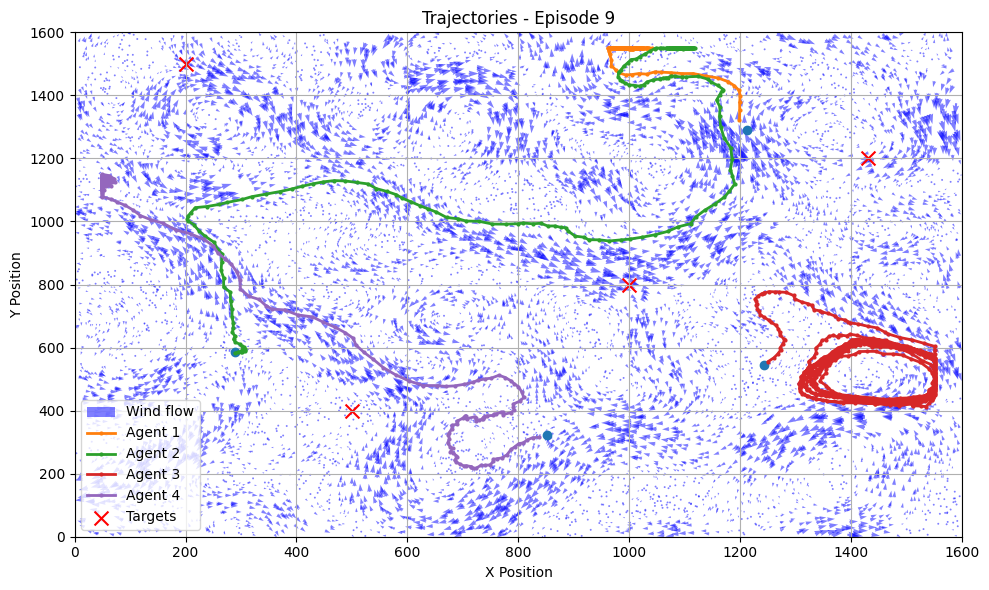

[dbg] r_i: [ -0. 450.  -0.  -0.]  loop_penalty: 0.000
[ep 10] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.12  -0.082 -0.974 -0.102]  loop_penalty: 0.101
[ep 10] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.401 -0.104 -1.079 -0.425]  loop_penalty: 0.424
[ep 10] r_central: 0.302 | coverage: 0.201, separation: 0.000
[dbg] r_i: [-0.804 -0.607 -1.64  -0.763]  loop_penalty: 0.762
[ep 10] r_central: 0.392 | coverage: 0.261, separation: 0.000
[dbg] r_i: [-0.902 -0.968 -1.884 -1.129]  loop_penalty: 1.128
[ep 10] r_central: 0.436 | coverage: 0.291, separation: 0.000
[dbg] r_i: [-1.044 -1.423 -2.418 -1.427]  loop_penalty: 1.426
[ep 10] r_central: 0.449 | coverage: 0.300, separation: 0.000
[dbg] r_i: [-1.256 -3.401 -2.433 -1.699]  loop_penalty: 1.697
[ep 10] r_central: 0.477 | coverage: 0.318, separation: 0.000
[dbg] r_i: [-1.284 -4.638 -3.006 -1.743]  loop_penalty: 1.741
[ep 10] r_central: 0.477 | coverage: 0.318, separation: 0.000
[dbg] r_i: [-1

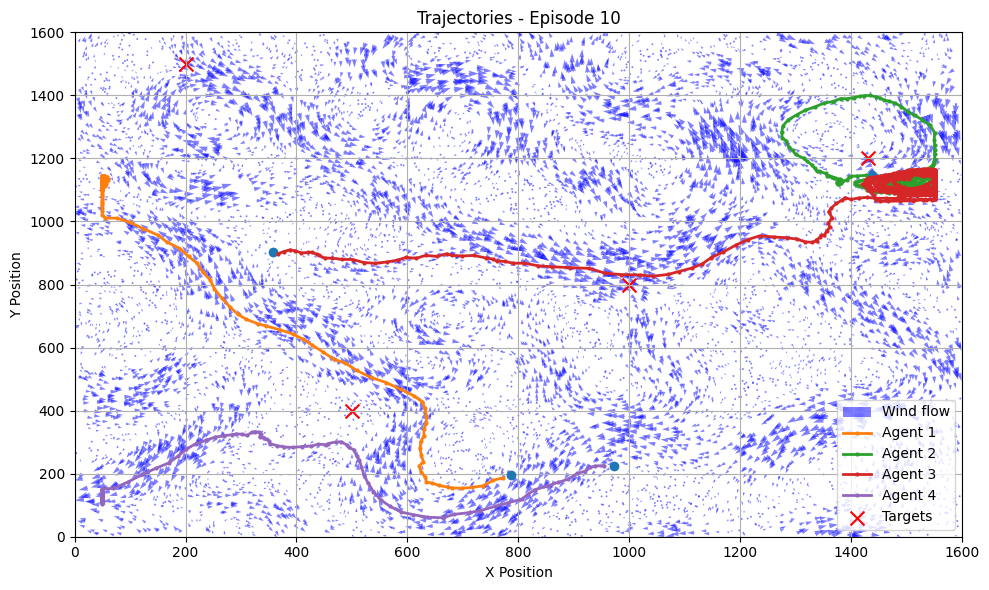

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 11] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.27  -0.014 -2.165 -0.142]  loop_penalty: 0.142
[ep 11] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.457 -0.715 -2.895 -0.908]  loop_penalty: 0.908
[ep 11] r_central: 0.302 | coverage: 0.201, separation: 0.000
[dbg] r_i: [-0.535 -1.434 -3.137 -1.472]  loop_penalty: 1.471
[ep 11] r_central: 0.361 | coverage: 0.241, separation: 0.000
[dbg] r_i: [-0.77  -1.511 -4.408 -1.689]  loop_penalty: 1.688
[ep 11] r_central: 0.380 | coverage: 0.253, separation: 0.000
[dbg] r_i: [-0.81  -1.597 -5.001 -1.767]  loop_penalty: 1.766
[ep 11] r_central: 0.430 | coverage: 0.287, separation: 0.000
[dbg] r_i: [-0.856 -1.831 -5.001 -1.906]  loop_penalty: 1.905
[ep 11] r_central: 0.446 | coverage: 0.298, separation: 0.000
[dbg] r_i: [-0.885 -1.914 -5.002 -2.029]  loop_penalty: 2.027
[ep 11] r_central: 0.471 | coverage: 0.314, separation: 0.000
[dbg] r_i: [-1.104

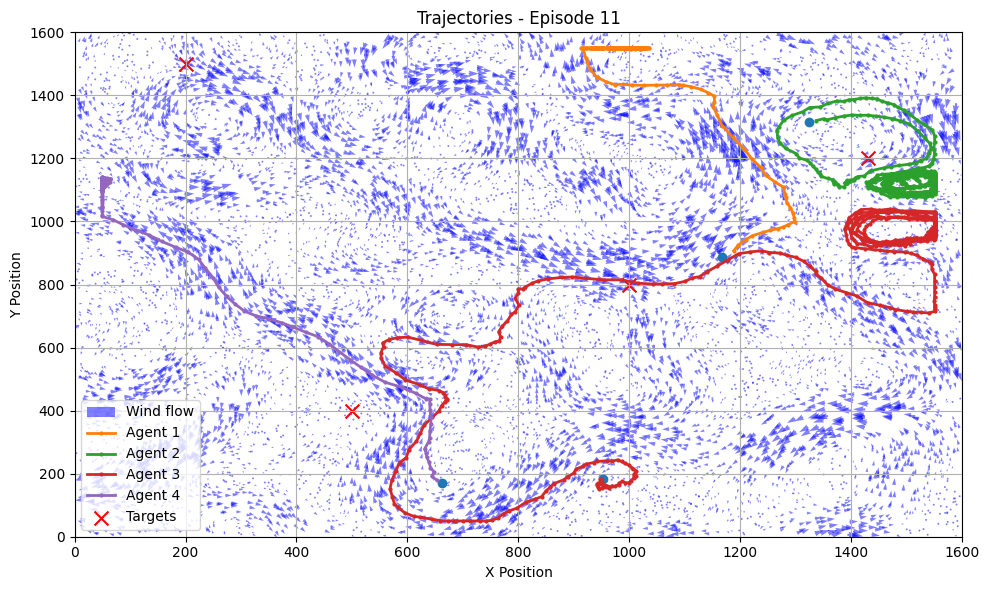

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 12] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-1.165 -0.727 -0.657 -0.319]  loop_penalty: 0.319
[ep 12] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-1.797 -0.98  -1.281 -0.594]  loop_penalty: 0.593
[ep 12] r_central: 0.302 | coverage: 0.201, separation: 0.000
[dbg] r_i: [-1.89  -0.985 -1.643 -0.944]  loop_penalty: 0.943
[ep 12] r_central: 0.330 | coverage: 0.220, separation: 0.000
[dbg] r_i: [-1.957 -1.873 -1.689 -1.308]  loop_penalty: 1.307
[ep 12] r_central: 0.353 | coverage: 0.235, separation: 0.000
[dbg] r_i: [-2.907 -2.519 -1.73  -2.217]  loop_penalty: 2.216
[ep 12] r_central: 0.377 | coverage: 0.251, separation: 0.000
[dbg] r_i: [-3.364 -2.825 -2.067 -3.318]  loop_penalty: 3.317
[ep 12] r_central: 0.395 | coverage: 0.263, separation: 0.000
[dbg] r_i: [-3.947 -2.904 -2.485 -4.317]  loop_penalty: 4.315
[ep 12] r_central: 0.433 | coverage: 0.289, separation: 0.000
[dbg] r_i: [-4.597

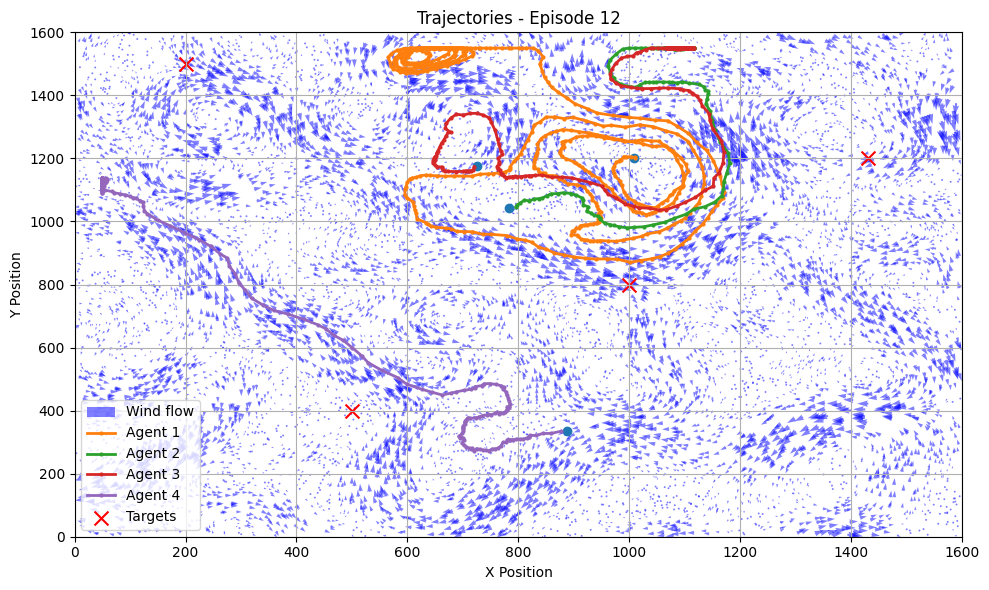

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 13] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.16  -0.017 -0.083 -0.377]  loop_penalty: 0.377
[ep 13] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.267 -0.049 -0.196 -0.847]  loop_penalty: 0.846
[ep 13] r_central: 0.369 | coverage: 0.246, separation: 0.000
[dbg] r_i: [-0.587 -0.586 -0.266 -1.095]  loop_penalty: 1.094
[ep 13] r_central: 0.406 | coverage: 0.271, separation: 0.000
[dbg] r_i: [-0.863 -0.609 -0.626 -1.495]  loop_penalty: 1.494
[ep 13] r_central: 0.441 | coverage: 0.294, separation: 0.000
[dbg] r_i: [-1.197 -1.238 -0.683 -1.708]  loop_penalty: 1.707
[ep 13] r_central: 0.490 | coverage: 0.326, separation: 0.000
[dbg] r_i: [-1.222 -1.559 -1.037 -1.959]  loop_penalty: 1.958
[ep 13] r_central: 0.501 | coverage: 0.334, separation: 0.000
[dbg] r_i: [-1.664 -1.973 -1.18  -2.27 ]  loop_penalty: 2.269
[ep 13] r_central: 0.512 | coverage: 0.342, separation: 0.000
[dbg] r_i: [-2.091

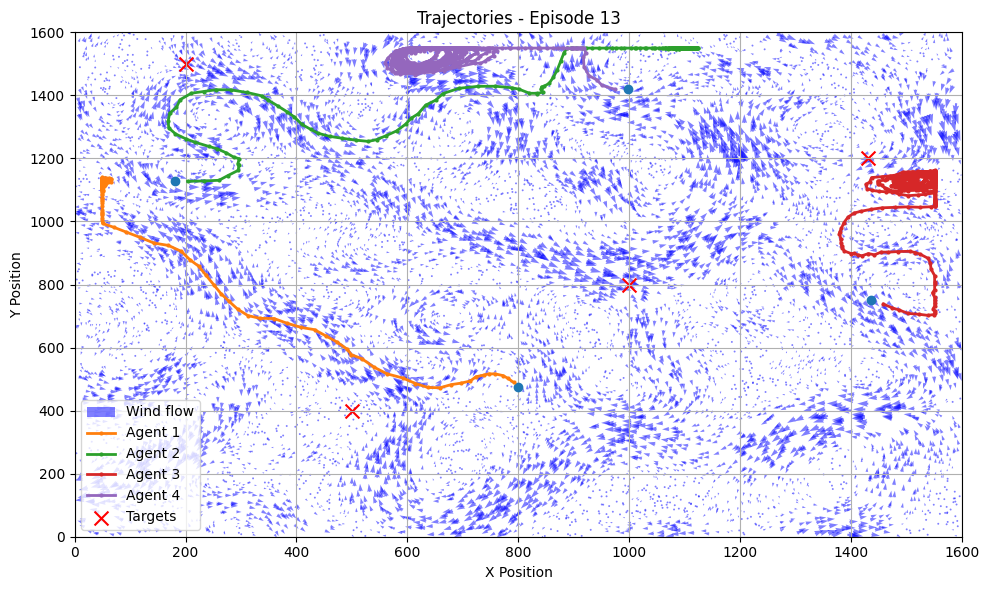

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 14] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.414 -0.362 -0.555 -0.062]  loop_penalty: 0.061
[ep 14] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.498 -0.563 -0.752 -0.127]  loop_penalty: 0.126
[ep 14] r_central: 0.369 | coverage: 0.246, separation: 0.000
[dbg] r_i: [-0.819 -0.677 -0.787 -0.273]  loop_penalty: 0.272
[ep 14] r_central: 0.459 | coverage: 0.306, separation: 0.000
[dbg] r_i: [-1.149 -1.057 -1.038 -0.591]  loop_penalty: 0.590
[ep 14] r_central: 0.470 | coverage: 0.313, separation: 0.000
[dbg] r_i: [-1.269 -1.257 -1.524 -0.634]  loop_penalty: 0.633
[ep 14] r_central: 0.476 | coverage: 0.317, separation: 0.000
[dbg] r_i: [-1.495 -1.402 -1.685 -0.679]  loop_penalty: 0.677
[ep 14] r_central: 0.518 | coverage: 0.345, separation: 0.000
[dbg] r_i: [-1.691 -1.882 -1.692 -0.735]  loop_penalty: 0.734
[ep 14] r_central: 0.533 | coverage: 0.355, separation: 0.000
[dbg] r_i: [-2.201

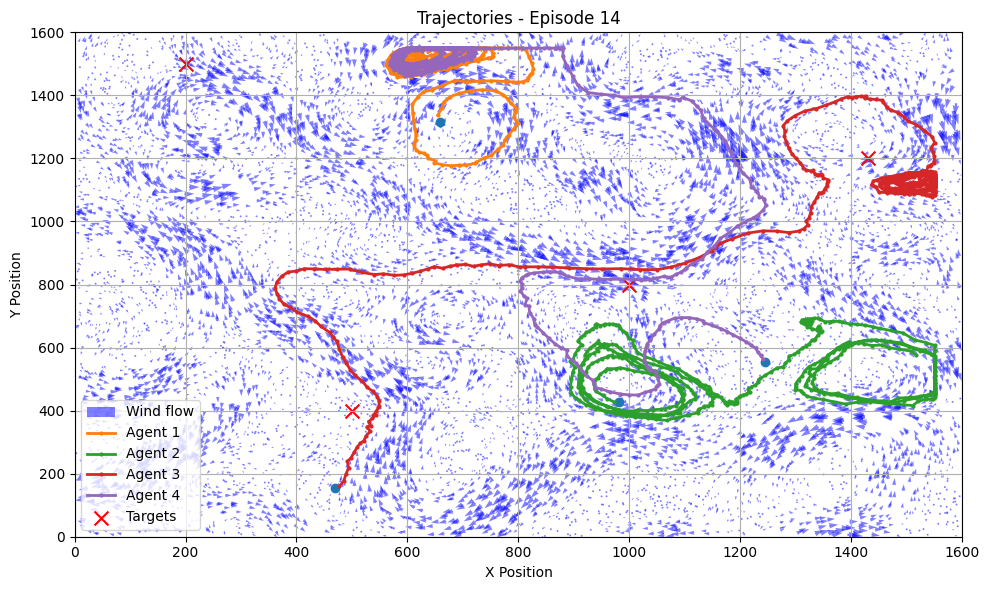

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 15] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.155 -1.049 -0.093 -0.012]  loop_penalty: 0.011
[ep 15] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.275 -1.661 -0.223 -0.162]  loop_penalty: 0.161
[ep 15] r_central: 0.336 | coverage: 0.224, separation: 0.000
[dbg] r_i: [-0.364 -2.305 -0.664 -0.21 ]  loop_penalty: 0.209
[ep 15] r_central: 0.383 | coverage: 0.256, separation: 0.000
[dbg] r_i: [-0.456 -2.444 -1.612 -0.255]  loop_penalty: 0.254
[ep 15] r_central: 0.424 | coverage: 0.283, separation: 0.000
[dbg] r_i: [-1.134 -3.567 -1.931 -0.43 ]  loop_penalty: 0.429
[ep 15] r_central: 0.454 | coverage: 0.303, separation: 0.000
[dbg] r_i: [-1.428 -4.353 -2.358 -0.491]  loop_penalty: 0.490
[ep 15] r_central: 0.500 | coverage: 0.333, separation: 0.000
[dbg] r_i: [-2.23  -5.002 -3.053 -1.048]  loop_penalty: 1.047
[ep 15] r_central: 0.514 | coverage: 0.342, separation: 0.000
[dbg] r_i: [-3.383

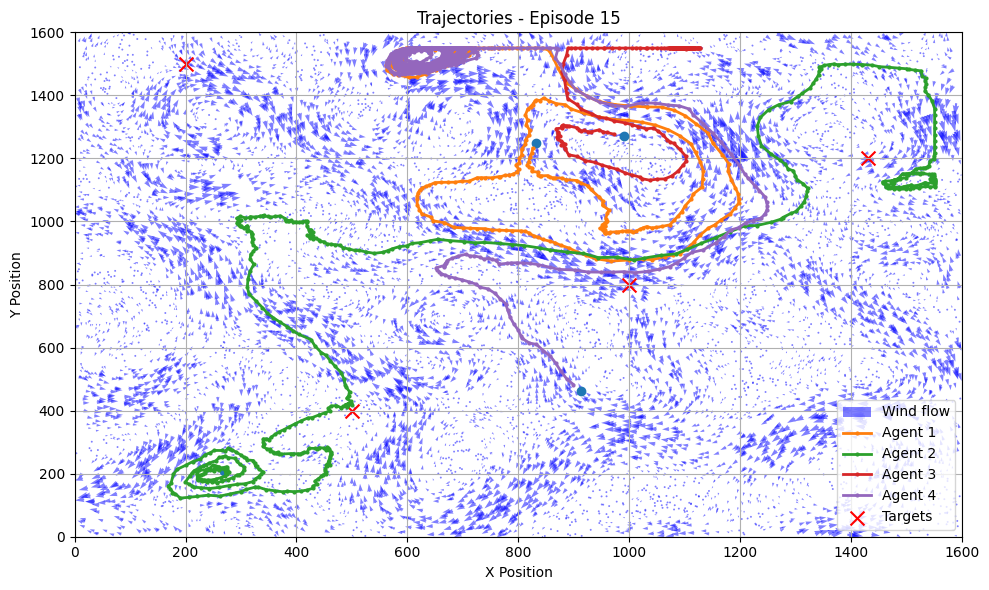

[dbg] r_i: [ -0.  -0. 450.  -0.]  loop_penalty: 0.000
[ep 16] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.101 -0.215 -0.264 -0.693]  loop_penalty: 0.692
[ep 16] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.172 -0.242 -0.794 -0.791]  loop_penalty: 0.790
[ep 16] r_central: 0.302 | coverage: 0.201, separation: 0.000
[dbg] r_i: [-0.366 -0.753 -0.982 -0.835]  loop_penalty: 0.834
[ep 16] r_central: 0.361 | coverage: 0.241, separation: 0.000
[dbg] r_i: [-0.955 -1.062 -1.105 -1.276]  loop_penalty: 1.275
[ep 16] r_central: 0.413 | coverage: 0.276, separation: 0.000
[dbg] r_i: [-1.182 -1.343 -1.203 -1.535]  loop_penalty: 1.534
[ep 16] r_central: 0.417 | coverage: 0.278, separation: 0.000
[dbg] r_i: [-1.836 -2.016 -1.226 -1.539]  loop_penalty: 1.538
[ep 16] r_central: 0.446 | coverage: 0.298, separation: 0.000
[dbg] r_i: [-2.413 -2.212 -1.652 -1.646]  loop_penalty: 1.644
[ep 16] r_central: 0.491 | coverage: 0.327, separation: 0.000
[dbg] r_i: [-2

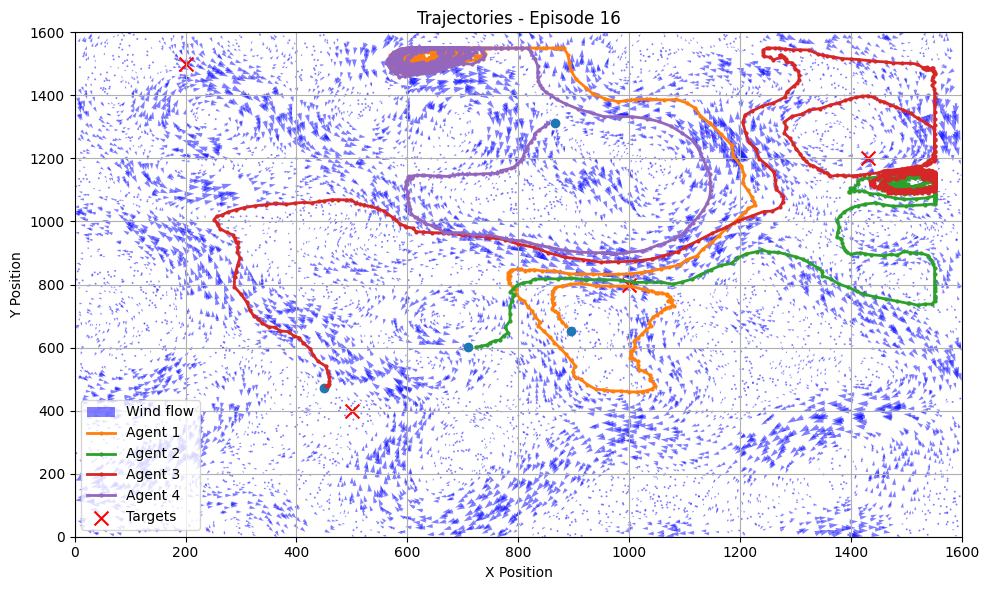

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 17] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.222 -0.944 -0.212 -0.193]  loop_penalty: 0.193
[ep 17] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.243 -0.96  -0.228 -0.259]  loop_penalty: 0.258
[ep 17] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.384 -1.013 -0.409 -0.266]  loop_penalty: 0.265
[ep 17] r_central: 0.361 | coverage: 0.241, separation: 0.000
[dbg] r_i: [-0.465 -1.028 -0.565 -0.343]  loop_penalty: 0.342
[ep 17] r_central: 0.447 | coverage: 0.298, separation: 0.000
[dbg] r_i: [-7.06000e-01  4.48954e+02 -6.63000e-01 -4.29000e-01]  loop_penalty: 0.428
[ep 17] r_central: 0.495 | coverage: 0.330, separation: 0.000
[dbg] r_i: [-1.027 -1.113 -0.698 -0.473]  loop_penalty: 0.471
[ep 17] r_central: 0.507 | coverage: 0.338, separation: 0.000
[dbg] r_i: [-1.185 -1.218 -0.837 -0.615]  loop_penalty: 0.613
[ep 17] r_central: 0.552 | coverage: 0.368, separation: 

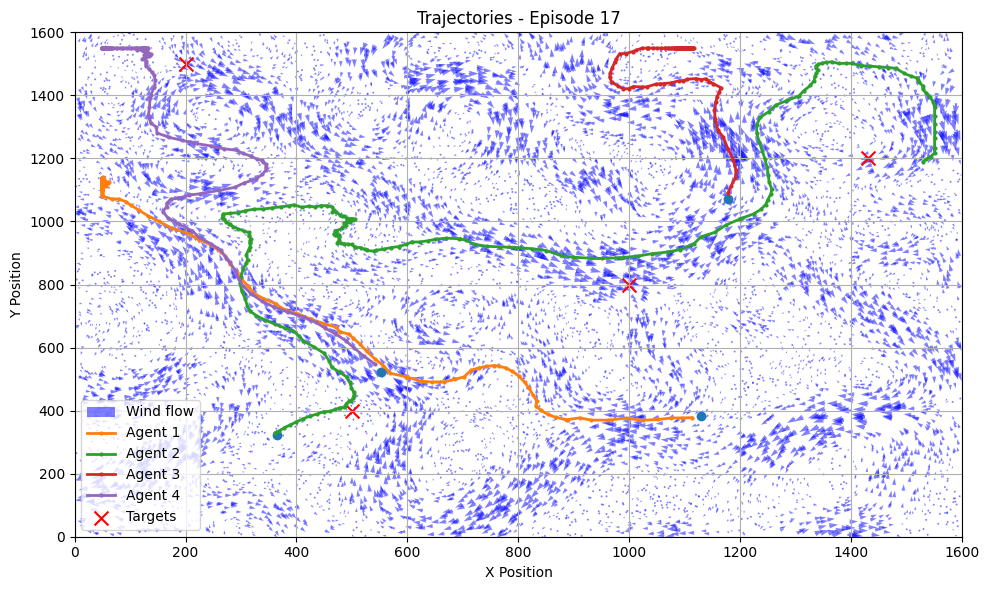

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 18] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.723 -0.166 -0.076 -0.099]  loop_penalty: 0.098
[ep 18] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.782 -0.302 -0.289 -0.224]  loop_penalty: 0.224
[ep 18] r_central: 0.336 | coverage: 0.224, separation: 0.000
[dbg] r_i: [-1.129 -0.345 -0.451 -0.624]  loop_penalty: 0.623
[ep 18] r_central: 0.406 | coverage: 0.271, separation: 0.000
[dbg] r_i: [-1.267 -0.502 -0.619 -0.923]  loop_penalty: 0.922
[ep 18] r_central: 0.464 | coverage: 0.309, separation: 0.000
[dbg] r_i: [-1.469 -0.841 -0.912 -1.359]  loop_penalty: 1.357
[ep 18] r_central: 0.522 | coverage: 0.348, separation: 0.000
[dbg] r_i: [-1.518 -0.976 -1.177 -1.973]  loop_penalty: 1.971
[ep 18] r_central: 0.533 | coverage: 0.355, separation: 0.000
[dbg] r_i: [-1.6   -1.003 -1.241 -2.16 ]  loop_penalty: 2.159
[ep 18] r_central: 0.539 | coverage: 0.359, separation: 0.000
[dbg] r_i: [-1.833

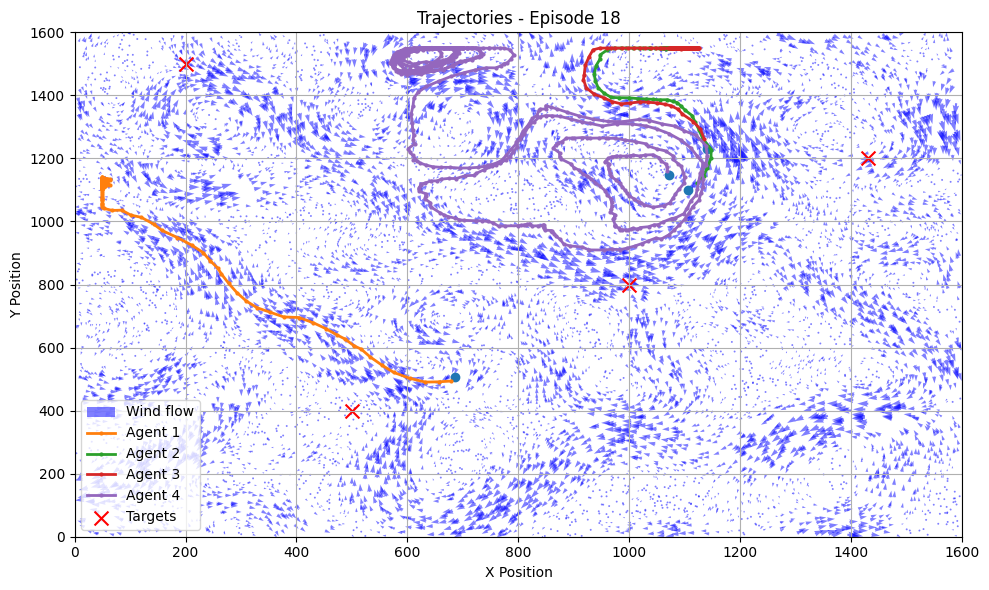

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 19] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.098 -0.102 -0.146 -0.445]  loop_penalty: 0.445
[ep 19] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.299 -0.183 -0.433 -1.272]  loop_penalty: 1.271
[ep 19] r_central: 0.403 | coverage: 0.269, separation: 0.000
[dbg] r_i: [-0.308 -0.271 -0.53  -1.56 ]  loop_penalty: 1.559
[ep 19] r_central: 0.414 | coverage: 0.276, separation: 0.000
[dbg] r_i: [-0.496 -0.32  -0.835 -1.587]  loop_penalty: 1.586
[ep 19] r_central: 0.470 | coverage: 0.313, separation: 0.000
[dbg] r_i: [-0.551 -0.412 -1.428 -1.818]  loop_penalty: 1.817
[ep 19] r_central: 0.500 | coverage: 0.333, separation: 0.000
[dbg] r_i: [-0.97  -0.482 -1.675 -1.995]  loop_penalty: 1.994
[ep 19] r_central: 0.533 | coverage: 0.355, separation: 0.000
[dbg] r_i: [-1.403 -0.625 -2.228 -2.285]  loop_penalty: 2.283
[ep 19] r_central: 0.575 | coverage: 0.383, separation: 0.000
[dbg] r_i: [-1.404

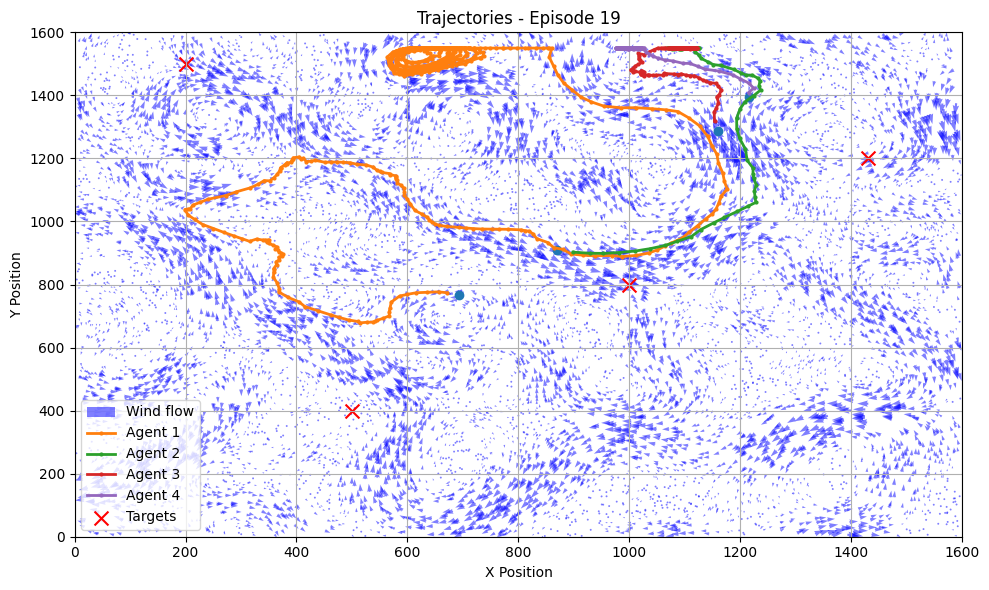

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 20] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.299 -0.889 -0.046 -0.094]  loop_penalty: 0.093
[ep 20] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [ 4.4945e+02 -2.2320e+00 -6.4300e-01 -4.0800e-01]  loop_penalty: 0.407
[ep 20] r_central: 0.369 | coverage: 0.246, separation: 0.000
[dbg] r_i: [-0.703 -4.247 -1.023 -0.423]  loop_penalty: 0.422
[ep 20] r_central: 0.414 | coverage: 0.276, separation: 0.000
[dbg] r_i: [-0.857 -4.336 -1.175 -0.463]  loop_penalty: 0.462
[ep 20] r_central: 0.447 | coverage: 0.298, separation: 0.000
[dbg] r_i: [-1.072 -5.001 -1.704 -0.633]  loop_penalty: 0.632
[ep 20] r_central: 0.473 | coverage: 0.315, separation: 0.000
[dbg] r_i: [-1.377 -5.001 -1.778 -0.678]  loop_penalty: 0.676
[ep 20] r_central: 0.484 | coverage: 0.322, separation: 0.000
[dbg] r_i: [-1.66  -5.002 -2.025 -0.784]  loop_penalty: 0.783
[ep 20] r_central: 0.500 | coverage: 0.334, separation: 0.00

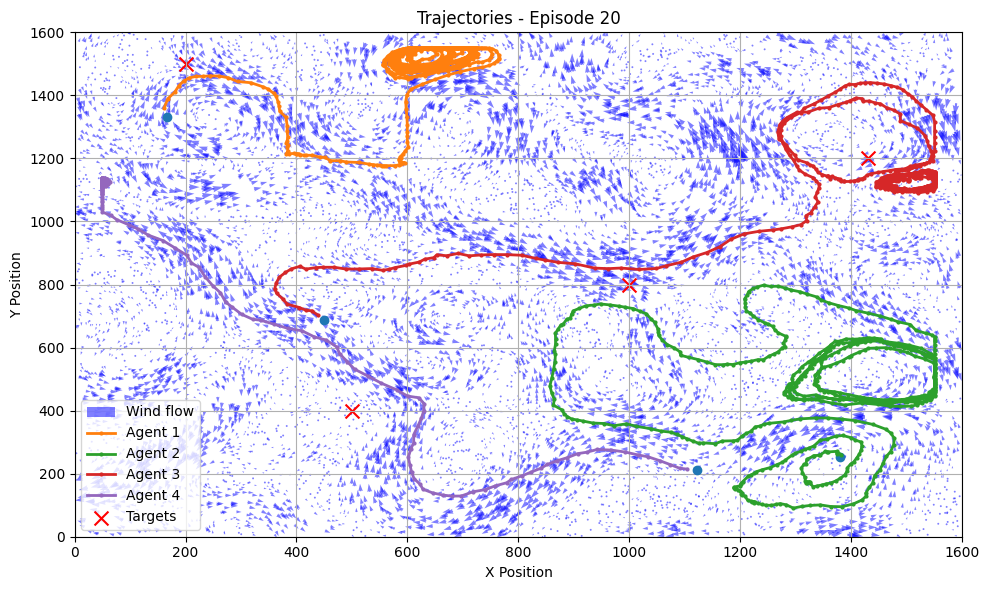

[dbg] r_i: [ -0.  -0.  -0. 450.]  loop_penalty: 0.000
[ep 21] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.426 -0.075 -0.025 -1.108]  loop_penalty: 1.108
[ep 21] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.485 -0.421 -0.344 -3.007]  loop_penalty: 3.006
[ep 21] r_central: 0.336 | coverage: 0.224, separation: 0.000
[dbg] r_i: [-0.544 -0.68  -1.045 -4.322]  loop_penalty: 4.321
[ep 21] r_central: 0.361 | coverage: 0.241, separation: 0.000
[dbg] r_i: [-0.75  -0.68  -1.25  -4.866]  loop_penalty: 4.865
[ep 21] r_central: 0.397 | coverage: 0.264, separation: 0.000
[dbg] r_i: [-0.896 -0.708 -1.617 -5.001]  loop_penalty: 5.000
[ep 21] r_central: 0.422 | coverage: 0.281, separation: 0.000
[dbg] r_i: [-0.911 -0.732 -1.69  -5.001]  loop_penalty: 5.000
[ep 21] r_central: 0.430 | coverage: 0.287, separation: 0.000
[dbg] r_i: [-1.14  -1.028 -1.904 -5.002]  loop_penalty: 5.000
[ep 21] r_central: 0.487 | coverage: 0.324, separation: 0.000
[dbg] r_i: [-1

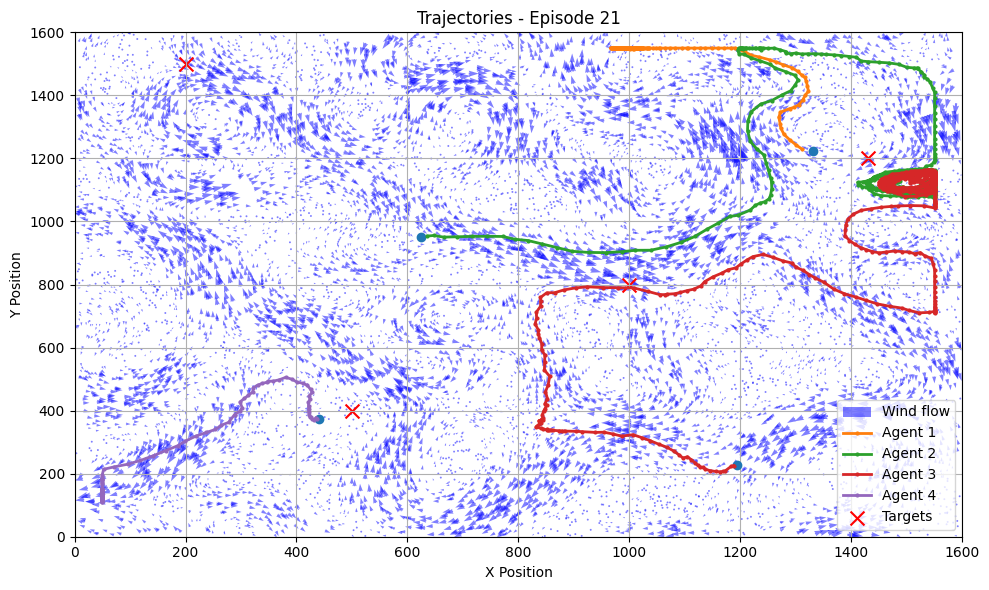

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 22] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.054 -0.196 -2.455 -0.034]  loop_penalty: 0.034
[ep 22] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.372 -0.582 -4.483 -0.075]  loop_penalty: 0.075
[ep 22] r_central: 0.369 | coverage: 0.246, separation: 0.000
[dbg] r_i: [-0.56  -0.609 -5.001 -0.108]  loop_penalty: 0.107
[ep 22] r_central: 0.437 | coverage: 0.291, separation: 0.000
[dbg] r_i: [-0.577 -0.728 -5.001 -0.148]  loop_penalty: 0.147
[ep 22] r_central: 0.447 | coverage: 0.298, separation: 0.000
[dbg] r_i: [-0.71  -1.769 -5.001 -0.385]  loop_penalty: 0.383
[ep 22] r_central: 0.490 | coverage: 0.326, separation: 0.000
[dbg] r_i: [-0.77  -2.149 -5.001 -0.53 ]  loop_penalty: 0.529
[ep 22] r_central: 0.511 | coverage: 0.341, separation: 0.000
[dbg] r_i: [-0.795 -2.358 -5.002 -0.619]  loop_penalty: 0.617
[ep 22] r_central: 0.556 | coverage: 0.370, separation: 0.000
[dbg] r_i: [-0.826

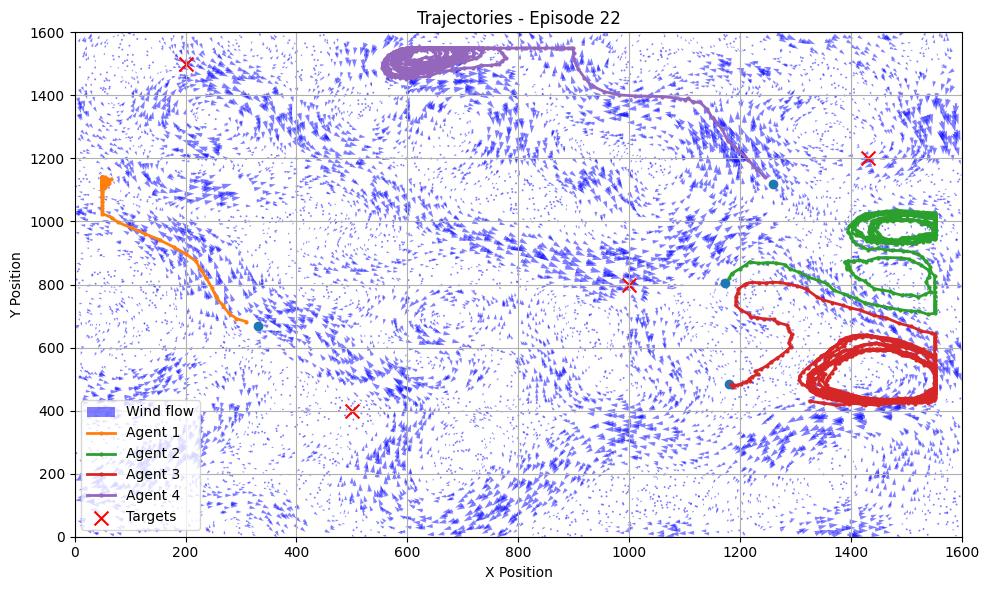

[dbg] r_i: [-0. -0. -0. -0.]  loop_penalty: 0.000
[ep 23] r_central: -0.000 | coverage: -0.000, separation: 0.000
[dbg] r_i: [-0.111 -0.014 -0.157 -0.076]  loop_penalty: 0.075
[ep 23] r_central: 0.269 | coverage: 0.179, separation: 0.000
[dbg] r_i: [-0.49  -0.132 -0.198 -0.223]  loop_penalty: 0.223
[ep 23] r_central: 0.369 | coverage: 0.246, separation: 0.000
[dbg] r_i: [-0.802 -0.399 -0.449 -0.582]  loop_penalty: 0.581
[ep 23] r_central: 0.383 | coverage: 0.256, separation: 0.000
[dbg] r_i: [-1.064 -0.517 -0.528 -0.595]  loop_penalty: 0.594
[ep 23] r_central: 0.464 | coverage: 0.309, separation: 0.000
[dbg] r_i: [-1.074 -0.966 -0.759 -0.855]  loop_penalty: 0.854
[ep 23] r_central: 0.522 | coverage: 0.348, separation: 0.000
[dbg] r_i: [-1.188 -1.293 -0.828 -1.136]  loop_penalty: 1.135
[ep 23] r_central: 0.544 | coverage: 0.363, separation: 0.000
[dbg] r_i: [-1.211 -1.554 -0.899 -1.345]  loop_penalty: 1.344
[ep 23] r_central: 0.584 | coverage: 0.390, separation: 0.000
[dbg] r_i: [-1.221

KeyboardInterrupt: 

In [33]:
#============================================================================================
#=====================================Training Loop==========================================
#============================================================================================

# Outer Loop: Iterates over max_episodes=2000 episodes.
# Inner Loop: Runs up to max_steps=100
exploration_std = 1.0
for ep in range(max_episodes):
    start_time = time.time()  # Start time for the episode
    Dpos = [np.random.randint(150, 1450, size=2) for _ in range(num_agents)]
    x = np.zeros(num_agents)
    y = np.zeros(num_agents)

    for j in range(num_agents):
        cd = Dpos[j]
        x[j] = cd[0]
        y[j] = cd[1]




    DVel = [np.array([constV, 0]) for _ in range(num_agents)]
    W_x_y = []

    prev_vels = [np.array([0.0, 0.0]) for _ in range(num_agents)]
    new_vels  = [np.array([0.0, 0.0]) for _ in range(num_agents)]

    grid_size = Dim // 32  # 50 for 1600x1600 grid with 32px cells
    visit_grid = np.zeros((grid_size, grid_size))
    recent_visit_grid = np.zeros_like(visit_grid)
    turn_history = [[] for _ in range(num_agents)]

    for pos in Dpos:
        wvx = interp_fvx(pos).item() * wind_scale_fac
        wvy = interp_fvy(pos).item() * wind_scale_fac
        W_x_y.append(np.array([wvx, wvy]))
    visited_targets = [False] * len(Tpos)  # Initialize visited targets
    episode_rewards = []  # List to store total rewards for each episode
    SX = 0
    initial_tau = 1.0
    min_tau = 0.1
    tau_decay = 0.995
    tau = initial_tau
    visited_targets = [False]*len(Tpos)           # MOD‑2: reset every episode
    count_step = 0
    curr_rew = 0
    TotolTime = 0
    prev_agent_positions = [pos.copy() for pos in Dpos]      # ✱ NEW (1)
    agent_trajectories = [[] for _ in range(num_agents)] # Store trajectories
    episode_trajectories = [[] for _ in range(num_agents)]  # Reset trajectories for the episode
    loop_detectors = [LoopDetector() for _ in range(num_agents)]
    #vortex_penalty = 100.0  # tune this

    while SX != 1 and count_step < max_steps:
        TotolTime += 1
        count_step += 1
        states = []
        actions = []
        agent_positions = np.zeros((num_agents, 2))

        # Act for each agent
        for i in range(num_agents):
            state = np.concatenate([Dpos[i], DVel[i], W_x_y[i]]) # Constructs state (6D: position, velocity, wind).
            state_t = torch.tensor(state, dtype=torch.float32).to(device) # Converts to PyTorch tensor and passes through actor network to get action probabilities.
            #probs = actor_networks[i](state_t.unsqueeze(0))
            #action = torch.argmax(probs, dim=-1).item() # Selects action with the highest probability.
            #action = actor_networks[i](state_t.unsqueeze(0)).squeeze(0).detach().cpu().numpy()
            raw_action = actor_networks[i](state_t.unsqueeze(0)).squeeze(0).detach().cpu().numpy()
            noise = np.random.normal(0, exploration_std, size=raw_action.shape)
            noisy_action = np.clip(raw_action + noise, -1.0, 1.0)
            action = noisy_action



            env_state = state
            wind_v = env_state[4:6]
            # update the agent's position and velocity based on the action taken
            new_x, new_y, new_vx, new_vy, w_dir, _, _, new_awvx, new_awvy = act(
                action, TotolTime, env_state[2], env_state[3], wind_v, env_state[0], env_state[1], px, py, pvx, pvy


            ) # action + 1 is used to match the action space (1-9).
            #return new_x, new_y, vx, vy, w_dir, int_vx, int_vy, wvx, wvy
            # ------------------------------------------------------------------
            # 2) quick diagnostic – is wind overpowering the motor?
            # ------------------------------------------------------------------
            wind_mag   = np.linalg.norm([new_awvx,new_awvy])                 # speed of wind (m/s)
            engine_mag = np.linalg.norm([new_vx, new_vy])       # == constV (10 m/s)
            ground_vx  = new_vx                      # resulting ground speed
            ground_vy  = new_vy
            ground_mag = np.linalg.norm([ground_vx, ground_vy])

            wind_dominates = wind_mag > engine_mag              # boolean

            # initialise counter once per episode
            if count_step == 1:
                wind_dom_count = 0
            wind_dom_count += int(wind_dominates)

            if ep < 5:  # print only first 5 episodes
                print(f"[step {count_step:03d}] "
                f"wind {wind_mag:4.1f} | engine {engine_mag:4.1f} | "
                f"ground {ground_mag:4.1f} | wind>engine? {wind_dominates}")



            agent_positions[i] = [new_x, new_y]
            Dpos[i] = np.array([new_x, new_y])
            DVel[i] = np.array([new_vx, new_vy])
            prev_vels[i] = np.array([env_state[2],env_state[3]])
            new_vels[i] = np.array([new_vx, new_vy])
            W_x_y[i] = np.array([new_awvx, new_awvy])
            next_state = np.concatenate([Dpos[i], DVel[i], W_x_y[i]])





            states.append(state)
            actions.append(action)
            episode_trajectories[i].append(Dpos[i].copy())  # Store position for each agent

        # Compute rewards
        #total_rewards, visited_targets, r_i, r_centralized = compute_total_reward(
            #agent_positions, Tpos, visited_targets, DVel, W_x_y, w1, w2, w3, alpha, beta
        #)

        total_rewards, visited_targets, r_i, r_central, r_coverage, r_separation, loop_penalty = compute_total_reward(
            agent_positions,
            prev_agent_positions,                            # ✱ NEW (2)
            Tpos, visited_targets, DVel, W_x_y,
            visit_grid,recent_visit_grid,prev_vels,new_vels,w1, w2, w3,w4, alpha, beta, count_step = count_step
        )
        #curr_rew += np.sum(total_rewards)

        prev_agent_positions = [pos.copy() for pos in Dpos]  # ✱ NEW (3)
        if ep < 300 and count_step < 500:   # first 5 steps of first 3 episodes
            print(f"[dbg] r_i: {r_i.round(3)}  loop_penalty: {loop_penalty:.3f}")
            print(f"[ep {ep}] r_central: {r_central:.3f} | coverage: {r_coverage:.3f}, separation: {r_separation:.3f}")

        update_visit_grid(agent_positions, visit_grid, cell_size=32)





        gamma = 0.99
        curr_rew = gamma * curr_rew + np.sum(total_rewards)





        # Store experience

        global_states = np.concatenate(states) # Concatenates states of all agents (24D).
        #global_action = np.zeros((num_agents, action_dim)) # Initializes global action (36D).
        #for i, a in enumerate(actions):
            #global_action[i, a] = 1
        #global_action = global_action.flatten()
        global_action = np.concatenate(actions) # For continuous

        next_states = [np.concatenate([Dpos[i], DVel[i], W_x_y[i]]) for i in range(num_agents)]
        next_global_states = np.concatenate(next_states)

        replay_buffer.append((global_states, global_action, total_rewards, next_global_states)) # Stores experience in replay buffer.

        # Training
        if len(replay_buffer) >= batch_size:
            minibatch = random.sample(replay_buffer, batch_size) # Samples a batch of experiences from the replay buffer.
            # Efficiently prepare data for tensor creation
            states_array = np.array([x[0] for x in minibatch], dtype=np.float32)
            actions_array = np.array([x[1] for x in minibatch], dtype=np.float32)
            rewards_array = np.array([np.sum(x[2]) for x in minibatch], dtype=np.float32)
            next_states_array = np.array([x[3] for x in minibatch], dtype=np.float32)

            states_batch = torch.tensor(states_array, dtype=torch.float32).to(device)
            actions_batch = torch.tensor(actions_array, dtype=torch.float32).to(device)
            rewards_batch = torch.tensor(rewards_array, dtype=torch.float32).to(device)
            next_states_batch = torch.tensor(next_states_array, dtype=torch.float32).to(device)

            # Critic update
            next_actions = []
            for i in range(num_agents):
                next_state_i = next_states_batch[:, i * state_dim:(i + 1) * state_dim] # Extracts the state for agent i.
                next_probs = target_actors[i](next_state_i) # Passes through target actor network to get action probabilities.
                #next_action = torch.nn.functional.one_hot(next_probs.argmax(dim=-1), action_dim).float() # Selects action with the highest probability.
                next_action = target_actors[i](next_state_i) ## For continuous

                next_actions.append(next_action) # Stores action in a list.
            next_global_action = torch.cat(next_actions, dim=-1) # Concatenates actions of all agents (36D).
            q_next = target_critic(next_states_batch, next_global_action) # Computes Q-value for next states and actions.
            q_target = rewards_batch + discount * q_next.squeeze() # Computes target Q-value.
            q_pred = critic_network(states_batch, actions_batch).squeeze() # Computes predicted Q-value.
            critic_loss = ((q_pred - q_target) ** 2).mean() # Computes loss.

            critic_optimizer.zero_grad() # Resets gradients.
            critic_loss.backward() # Backpropagates loss.
            critic_optimizer.step() # Updates critic network.

            # Actor update
            for i in range(num_agents):
                state_i = states_batch[:, i * state_dim:(i + 1) * state_dim] # Extracts the state for agent i.
                #action_pred = actor_networks[i](state_i) # Passes through actor network to get action probabilities.
                # ### MOD‑7: use Gumbel-Softmax sampling for differentiable one-hot
                #logits = actor_networks[i](state_i)
                #action_pred = torch.nn.functional.gumbel_softmax(logits, tau=1.0, hard=True)
                #logits = actor_networks[i](state_i)
                #action_pred = torch.nn.functional.gumbel_softmax(logits, tau=tau, hard=True)
                action_pred = actor_networks[i](state_i)



                global_action_pred = torch.zeros(batch_size, action_dim * num_agents).to(device) # Initializes global action (36D).
                for j in range(num_agents):
                    if j == i:
                        global_action_pred[:, j * action_dim:(j + 1) * action_dim] = action_pred # Stores action in global action.
                    else:
                        global_action_pred[:, j * action_dim:(j + 1) * action_dim] = actions_batch[:, j * action_dim:(j + 1) * action_dim] # Keeps other agents' actions unchanged.
                q_value = critic_network(states_batch, global_action_pred) # Computes Q-value for current states and actions.
                actor_loss = -q_value.mean() # Computes loss for actor network.

                actor_optimizers[i].zero_grad() # Resets gradients.
                actor_loss.backward() # Backpropagates loss.
                actor_optimizers[i].step() # Updates actor network.

            # Soft update target networks
            for a, ta in zip(actor_networks, target_actors):
                for tp, p in zip(ta.parameters(), a.parameters()):
                    tp.data.copy_(tau * p.data + (1 - tau) * tp.data) # Soft update target actor network
            for tp, p in zip(target_critic.parameters(), critic_network.parameters()):
                tp.data.copy_(tau * p.data + (1 - tau) * tp.data) # Soft update target critic network
        # MOD‑3: early stop if all targets visited
        if all(visited_targets):
            print(f"[ep {ep}] All targets found. Total reward: {curr_rew:.2f}")
            break


    end_time = time.time()  # End time for the episode
    episode_time = end_time - start_time
    exploration_std = max(0.01, exploration_std * 0.995)



    print(f"Episode {ep} took {episode_time:.4f} seconds to run")
    if ep % 1 == 0 and count_step == max_steps:
        print(f"Episode {ep}, Reward: {curr_rew:.2f}") # Prints episode number and total reward every 100 episodes.
        print(visited_targets)

    episode_rewards.append(curr_rew)  # Store the total reward for the episode
    for i in range(num_agents):
        agent_trajectories[i].append(np.array(episode_trajectories[i]))
    tau = max(min_tau, tau * tau_decay)

    if ep % 50 == 0 and len(episode_rewards) >= 50:
        smoothed_reward = np.mean(episode_rewards[-50:])
        print(f"[ep {ep}] Smoothed Reward (last 50): {smoothed_reward:.2f}")

    print(f"[ep {ep}] Replay buffer size: {len(replay_buffer)}")

    plt.figure(figsize=(10, 6))
    # Wind flow field
    plt.quiver(px, py, pvx, pvy, color="blue", alpha=0.5, label="Wind flow")
    plt.plot(x,y,'o')
    plt.title(f'Trajectories - Episode {ep}')
    plt.xlabel('X Position')
    plt.ylabel('Y Position')

    for agent_id in range(num_agents):
        traj = agent_trajectories[agent_id][-1]
        if traj.shape[0] > 1:
            traj = np.array(traj)
            plt.plot(
                traj[:, 0], traj[:, 1],
                label=f'Agent {agent_id + 1}',
                linewidth=2,
                marker='o', markersize=2
            )
        else:
            print(f"[ep {ep}] Agent {agent_id} trajectory too short.")


    # Plot target positions
    plt.scatter(Tpos[:, 0], Tpos[:, 1], color='red', marker='x', s=100, label='Targets')

    plt.legend()
    plt.grid(True)
    plt.xlim(0, 1600)
    plt.ylim(0, 1600)
    plt.tight_layout()
    plt.show()






# Save trajectories (optional)
np.save('agent_trajectories.npy', agent_trajectories)
np.save('episode_rewards.npy', np.array(episode_rewards))  # Save the rewards





In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Load the data
agent_trajectories = np.load('agent_trajectories.npy')  # Shape: (num_agents, max_episodes, steps_per_episode, 2)
episode_rewards = np.load('episode_rewards.npy')  # Shape: (max_episodes,)

num_agents = agent_trajectories.shape[0]
max_episodes = agent_trajectories.shape[1]
Tpos = np.array([[1430, 1200], [1000, 800], [500, 400], [200, 1500]])  # Target positions

# --- Plotting the Trajectories in the Last Episode ---
plt.figure(figsize=(10, 8))
plt.title(f'Trajectories in Last Episode (Episode {max_episodes - 10})')
plt.xlabel('X Position')
plt.ylabel('Y Position')

for agent_id in range(num_agents):
    last_episode_trajectory = agent_trajectories[agent_id, max_episodes - 10]  # Get trajectory from the last episode
    plt.plot(
        last_episode_trajectory[:, 0], last_episode_trajectory[:, 1],
        label=f'Agent {agent_id + 1}'
    )

# Plot target locations
plt.scatter(Tpos[:, 0], Tpos[:, 1], color='red', marker='o', s=50, label='Targets')  # Plot targets

plt.legend()
plt.grid(True)
plt.show()

# --- Plotting Rewards Over Episodes ---
plt.figure(figsize=(10, 6))
plt.plot(episode_rewards)
plt.title('Total Rewards per Episode')
plt.xlabel('Episode Number')
plt.ylabel('Total Reward')
plt.grid(True)
plt.show()

In [ ]:
# -----------------------------------------------------------------------------
#  Drone‑swarm MADDPG template **with variable engine‑thrust options**
# -----------------------------------------------------------------------------
#  ‣ Discrete speed levels  : 0 / 5 / 10  m s⁻¹  ("hover / cruise / dash")
#  ‣ Continuous thrust head : (Δvx, Δvy)  in  [‑f_max , f_max]
#  ‣ Energy‑cost shaping    :  −c·‖engine_vel‖²  to reward using wind
#  ---------------------------------------------------------------------------
#  Flip the flags below to pick the control mode you want to run.
# -----------------------------------------------------------------------------

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# =====================================================================
# 1) Global switches ---------------------------------------------------
# =====================================================================
USE_DISCRETE_SPEEDS   = True   # 3‑level thrust ‑ keeps discrete action space
USE_CONTINUOUS_THRUST = False  # 2‑D thrust head    (set True → overrides above)

assert not (USE_DISCRETE_SPEEDS and USE_CONTINUOUS_THRUST), "Pick one mode!"

# =====================================================================
# 2) Action‑space definition ------------------------------------------
# =====================================================================
num_headings = 9
if USE_DISCRETE_SPEEDS:
    speeds = [0.0, 5.0, 10.0]              # hover / cruise / dash
    action_dim = num_headings * len(speeds)  # 27
else:
    # Continuous thrust: actor predicts Δvx, Δvy (normalised)
    thrust_max = 10.0                      # m/s equivalent thrust capability
    action_dim = 2                         # Δvx, Δvy

state_dim  = 6                             # pos_x, pos_y, v_x, v_y, w_x, w_y
num_agents = 4

# =====================================================================
# 3) Actor networks ----------------------------------------------------
# =====================================================================

class ActorDiscrete(nn.Module):
    """Maps 6‑D state → 27 logits (3 speeds × 9 headings)."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128), nn.ReLU(),
            nn.Linear(128, 128),       nn.ReLU(),
            nn.Linear(128, action_dim),
            nn.Softmax(dim=-1)
        )
    def forward(self, x):
        return self.net(x)

class ActorContinuous(nn.Module):
    """Maps 6‑D state → Δvx, Δvy in [‑1,1]; scale later to thrust_max."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128), nn.ReLU(),
            nn.Linear(128, 128),       nn.ReLU(),
            nn.Linear(128, action_dim),
            nn.Tanh()                 # outputs in (‑1,1)
        )
    def forward(self, x):
        return self.net(x)

# Pick actor class -----------------------------------------------------
Actor = ActorContinuous if USE_CONTINUOUS_THRUST else ActorDiscrete

# =====================================================================
# 4) Utility: heading → angle range -----------------------------------
# =====================================================================
_heading_ranges = {
    0: (80, 100),   1: (260, 280), 2: (-10, 10),
    3: (170, 190),  4: (11, 79),   5: (101, 169),
    6: (191, 259),  7: (281, 349), 8: (None, None)  # maintain dir
}

# =====================================================================
# 5) act() helpers -----------------------------------------------------
# =====================================================================

def act_discrete(action_idx, prev_int_vx, prev_int_vy, wind_v, pos_x, pos_y):
    """Decode discrete action → engine‑frame velocity, new position."""
    speed_idx   = action_idx // num_headings
    heading_idx = action_idx %  num_headings
    constV      = speeds[speed_idx]

    if heading_idx == 8:  # maintain previous direction (hover if V=0)
        if constV == 0:
            int_vx, int_vy = 0.0, 0.0
        else:
            angle_deg = np.degrees(np.arctan2(prev_int_vy, prev_int_vx))
            int_vx = constV * np.cos(np.radians(angle_deg))
            int_vy = constV * np.sin(np.radians(angle_deg))
    else:
        a_low, a_hi = _heading_ranges[heading_idx]
        angle_deg   = np.random.randint(a_low, a_hi)
        int_vx      = constV * np.cos(np.radians(angle_deg))
        int_vy      = constV * np.sin(np.radians(angle_deg))

    # ground velocity = engine + wind
    vx, vy = int_vx + wind_v[0], int_vy + wind_v[1]
    new_x, new_y = pos_x + vx, pos_y + vy
    return new_x, new_y, int_vx, int_vy, angle_deg


def act_continuous(delta_v, wind_v, pos_x, pos_y):
    """Continuous thrust: delta_v already scaled to ±thrust_max."""
    int_vx, int_vy = delta_v                                 # engine frame
    vx, vy = int_vx + wind_v[0], int_vy + wind_v[1]
    new_x, new_y = pos_x + vx, pos_y + vy
    return new_x, new_y, int_vx, int_vy

# Pick correct act -----------------------------------------------------
act_fn = act_continuous if USE_CONTINUOUS_THRUST else act_discrete

# =====================================================================
# 6) Energy‑cost shaping  ---------------------------------------------
# =====================================================================
THRUST_COST_COEF = 0.005  # reward -= c * |engine_vel|²  (tune 1e‑3…1e‑2)

# In compute_total_reward() just before returning r_i + team_bonus:
#   engine_v2 = np.sum(np.square(engine_vel), axis=‑1)  # vector of size n
#   r_i      -= THRUST_COST_COEF * engine_v2
# ---------------------------------------------------------------------
#  (You’ll call act_fn first, capture engine velocity, and pass it in.)
# ---------------------------------------------------------------------

# =====================================================================
# 7) Critic network stays unchanged – just ensure action_dim matches ----
# =====================================================================
class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        total_state_dim  = state_dim  * num_agents
        total_action_dim = action_dim * num_agents
        self.net = nn.Sequential(
            nn.Linear(total_state_dim + total_action_dim, 256), nn.ReLU(),
            nn.Linear(256, 256), nn.ReLU(),
            nn.Linear(256, 1))
    def forward(self, s, a):
        return self.net(torch.cat([s, a], dim=-1))

# =====================================================================
# 8) Training‑loop notes ----------------------------------------------
# =====================================================================
# • For DISCRETE mode nothing else changes – just remember action_dim=27.
# • Build one‑hot of size (27) per agent when storing in replay_buffer.
# • For CONTINUOUS mode use raw Δvx,Δvy (clipped to ±thrust_max) instead
#   of one‑hot, and adjust the actor loss (policy‑gradient) accordingly.
# ---------------------------------------------------------------------
# • The reward function must receive `engine_vel` for energy penalty.
# ---------------------------------------------------------------------

# The rest of your script (replay buffer, soft updates, etc.) remains
# as in your original code, parameterised by the new Actor and act_fn.
